# Don’t Stop ’til You Get Enough: Considerations of Audio Duration on Genre Classification in Deep Learning
**Daniel Bruning - 10/14/2026**

## Elevator Pitch

If you walk into a music store or browse for Michael Jackson online, how would you expect his music to be categorized? Under pop? Under R&B? Under local artists if you happened upon a record store in Gary, Indiana? Most artist and song genres appear intuitive if not obvious. Yet, depending on where you are, what you are familiar with, and who is doing the categorizing, our notions of what define a genre and what examples are true examples of a genre shift. Genre may function as a useful, marketable classification, yet the defining boundaries of what specific songs or artists they circumscribe is fluid and contested.

Now consider machine learning systems being tasked with classifying songs. Before a model can learn to classify music, someone must decide what genres exist, what songs belong to each category, and what characteristics distinguish one genre from another. These decisions define the data the model learns from and thus the predictions it makes in concluding where a song fits.

A common assumption in language model training is more data begets better model performance. If a few seconds of audio are useful then even more seconds should be better. Give it the full catalogue to learn from! If a model can identify a genre from a short excerpt then surely providing the full song should provide the best possible accuracy. Yet, the folks behind tuning machine learning systems frequently encounter diminishing returns in such pursuits. Additional data increases computational cost, storage requirements, and training time. Meanwhile, the resulting performance for all the additional resources and effort may become progressively smaller.

This project investigates whether such a point exists in music genre classification. By comparing performance across multiple architectures and clip lengths, this experiment asks a relatively straightforward question:

How much of a song does a model actually need before it can reliably recognize its genre?

If such a threshold exists, additional audio contributes little new information to the classification task beyond a certain threshold. This experiment was conducted to look at how various deep learning architectures perform when carrying out music genre classification using audio clips of durations between 1 and 30 seconds. It assesses the models' performance, their sensitivity to duration, behaviour specific to each genre, computational efficiency, generalisation properties, and the kinds of errors they make.

## Experimental Design

The experiment looked at the impact of audio duration on music genre classification using deep learning methods. Its main aim was to find out how audio clip length affects classification performance with regard to various neural network architectures and different musical genres.

The following eight models were assessed: CapsNet, CNN, CRNN, MLP, MobileNetV2, ResidualCNN, ShallowResNet, and VGG. The model architectures were trained and tested with audio excerpts of 1, 3, 5, 10, 15, 20, 25, and 30 seconds in length. Each experimental condition was repeated with the use of several different random seeds to evaluate robustness and minimise sensitivity to random initialisation.

The performance was assessed on classification accuracy, precision, recall, and the F1 score. Further analyses looked into training behaviour, generalisation characteristics, parameter efficiency, performance specific to genre, and systematic classification errors.

## The Dataset

This experiment used the GTZAN Genre Collection, one of the most widely used benchmark datasets for music genre recognition research. The dataset was introduced by George Tzanetakis and Perry Cook and contains 1,000 audio excerpts spanning ten musical genres with 100 recordings per genre. The collection was assembled from recordings obtained from CDs, radio broadcasts, and microphone recordings and has become a standard benchmark for evaluating music genre classification systems. Source: https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification

## Dataset Limitations

GTZAN remains one of the most frequently used benchmarks for music genre classification. However, several limitations do warrant mention, including potential recording duplicates, artist overlap, and labeling inconsistencies. Despite these limitations, GTZAN remains useful for controlled comparison of architectures, preprocessing strategies, and duration-based experimental conditions. Consequently, results reported in this notebook were interpreted as comparative evaluations within the GTZAN benchmark rather than definitive estimates of real-world genre-classification performance.

## Dataset Preparation Decisions

Several design decisions were implemented to facilitate valid comparison of classification performance across both audio durations and neural network architectures. A fixed song-level train, validation, and test split was established prior to experimentation and reused throughout all trials to ensure differences in performance could not be attributed to variation in dataset composition. Spectrograms were generated using a common preprocessing pipeline and resized to a uniform resolution of 128 × 128 pixels regardless of excerpt duration or model architecture. Each model was evaluated on the same set of audio durations, allowing clip length to function as a controlled independent variable. To further support comparability, preprocessing procedures, optimization strategies, stopping criteria, and evaluation metrics were standardized wherever possible. Collectively, these controls were intended to improve internal validity and ensure observed differences in performance reflected the effects of architecture and audio duration rather than methodological variation.

### Duration-Based Evaluation

The original GTZAN recordings are approximately 30 seconds in length. Rather than treating each recording as a single observation, duration-specific excerpts of 1, 3, 5, 10, 15, 20, 25, and 30 seconds were generated from the same source recordings. This approach enabled direct investigation of how the amount of available audio affects classification performance while holding all other recording characteristics constant. By deriving all durations from the same songs, the experimental design isolated excerpt length as the primary variable of interest.

### Spectrogram Representation

Audio excerpts were converted into Mel spectrograms prior to model training. Mel spectrograms provide a time-frequency representation preserves temporal and spectral information while transforming audio signals into a format compatible with image-based deep learning architectures. Using a common spectrogram representation across all experiments ensured performance differences could be attributed to model architecture and excerpt duration rather than differences in feature extraction methodology.

### Fixed Data Partitioning

A song-level partitioning strategy was employed to create training, validation, and test sets prior to model development. The resulting split file was reused for all architectures, durations, and experimental runs. This ensured every model was evaluated on identical observations and prevented variation in data partitioning to allow stronger comparisons across architectures or duration conditions.

### Multiple Random Seeds

Each experimental condition was repeated across multiple random seeds to reduce sensitivity to stochastic effects arising from parameter initialization, data shuffling, and optimization. Repeated trials enabled estimation of average performance and variability across runs, providing a more stable characterization of model behavior than any individual training instance. Aggregate statistics derived from these repeated experiments were subsequently used for comparative analysis and interpretation.

### Standardized Evaluation Framework

All architectures were evaluated using the same performance metrics, including accuracy, balanced accuracy, precision, recall, F1 score, top-2 accuracy, top-3 accuracy, and Cohen's kappa. Applying a consistent evaluation framework across models and duration conditions enabled direct comparison of performance trends and supported investigation of whether observed duration effects were specific to a given architecture or broadly consistent across different deep learning approaches.

## Model Selection
The architectures selected for this study were chosen to represent several commonly used approaches to image-based deep learning while remaining computationally feasible for repeated experimentation across multiple audio durations and random seeds. Model selection was guided by both prior use in music genre classification research and the broader computer vision literature, where spectrograms are frequently treated as image-like representations. More bluntly, I hunted through Kaggle and Google searches to find suggestions for models commonly used for music categorization purposes.

The convolutional neural network (CNN) served as the primary baseline architecture due to its widespread use in spectrogram classification tasks and its ability to learn local time-frequency patterns. A multilayer perceptron (MLP) was included as a non-convolutional baseline to evaluate the extent to which explicit spatial feature extraction contributes to performance. ResNet50 was selected as a representative deep residual architecture, allowing comparison against a substantially larger and more complex network. EfficientNetB0 was included as an example of a modern parameter-efficient convolutional architecture that has demonstrated strong performance across a variety of image classification tasks. MobileNetV2 was selected as a lightweight architecture designed to achieve competitive performance with reduced computational requirements. Finally, a convolutional recurrent neural network (CRNN) was included because it combines convolutional feature extraction with sequence modeling and therefore provides a useful test of whether architectures explicitly designed to capture temporal dependencies respond differently to longer audio excerpts.

These models were not intended to identify a single optimal architecture for music genre classification. They were selected to represent diverse architectural approaches and to support investigation of whether the relationship between excerpt duration and classification performance is specific to or consistent across models with differing inductive biases, parameter counts, and learning mechanisms.

## Imports

In [ ]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import t, ttest_rel

RESULTS_DIR = Path("results/gtzan")

architectures = sorted(
    [
        p.name
        for p in RESULTS_DIR.iterdir()
        if p.is_dir()
    ]
)

GENRES = [
    "blues",
    "classical",
    "country",
    "disco",
    "hiphop",
    "jazz",
    "metal",
    "pop",
    "reggae",
    "rock"
]

## Helper functions

In [2]:
def display_table(df, decimals=4):
    display(
        df.style
          .hide(axis="index")
          .format(precision=decimals)
    )

# 1. Experimental Artifacts and Data Assembly

## Inventory Dataframe

This dataframe inventories the experimental artifacts generated for each architecture, including duration results, genre results, training histories, metadata files, and confusion matrices. It provides a reproducibility check and helps verify all expected outputs were successfully generated prior to analysis.

In [ ]:
inventory_records = []

for model in architectures:
    model_path = RESULTS_DIR / model

    inventory_records.append({
        "model": model,
        "duration_results": len(
            list(
                (model_path / "duration_results").glob("*")
            )
        ),
        "histories": len(
            list(
                (model_path / "histories").glob("*")
            )
        ),
        "metadata": len(
            list(
                (model_path / "metadata").glob("*")
            )
        ),
        "confusion_matrices": len(
            list(
                (model_path / "confusion_matrices").glob("*")
            )
        )
    })

artifact_inventory_df = pd.DataFrame(inventory_records)

# display_table(artifact_inventory_df)

## Metadata Dataframe

This dataframe contains architecture-level metadata and training configuration information including parameter counts, input dimensions, and dataset characteristics. It serves as reference for model specifications throughout the analysis.


In [4]:
metadata_frames = []

for model in architectures:

    metadata_files = list(
        (
            RESULTS_DIR
            / model
            / "metadata"
        ).glob("*.csv")
    )

    for file in metadata_files:
        metadata_frames.append(
            pd.read_csv(file)
        )

model_metadata_df = pd.concat(
    metadata_frames,
    ignore_index=True
)
display_table(model_metadata_df)

model,model_family,parameter_count,input_height,input_width,channels,num_classes,initial_learning_rate,train_samples,val_samples,test_samples
capsnet,Capsule,246154,128,128,3,10,0.0010,699,150,150
cnn,CNN,3305930,128,128,3,10,0.0010,699,150,150
crnn,Recurrent,189450,128,128,3,10,0.0001,699,150,150
mlp,Dense,3148570,128,128,3,10,0.0001,699,150,150
mobilenetv2,CNN,2588490,128,128,3,10,0.0001,699,150,150
residualcnn,ResNet,482506,128,128,3,10,0.0001,699,150,150
shallowresnet,ResNet,327178,128,128,3,10,0.0005,699,150,150
vgg,CNN,306602,128,128,3,10,0.0010,699,150,150


## Run Metrics Dataframe

This dataframe consolidates run-level experimental results across architectures, durations, and random seeds. It includes training, validation, and test metrics as well as engineered features used throughout the performance, efficiency, and generalization analyses.


In [51]:
run_frames = []

for model in architectures:

    summary_file = (
        RESULTS_DIR
        / model
        / "duration_results"
        / "experiment_summary_all.csv"
    )

    if summary_file.exists():
        run_frames.append(
            pd.read_csv(summary_file)
        )

run_summaries_df = pd.concat(
    run_frames,
    ignore_index=True
)

run_summaries_df = run_summaries_df.merge(
    model_metadata_df,
    on="model",
    how="left"
)

run_summaries_df["duration_seconds"] = (
    run_summaries_df["duration"]
    .str.replace("s", "", regex=False)
    .astype(int)
)

run_summaries_df["params_million"] = (
    run_summaries_df["parameter_count"] / 1_000_000
)

run_summaries_df["accuracy_per_million_params"] = (
    run_summaries_df["test_accuracy"]
    /
    run_summaries_df["params_million"]
)

run_summaries_df["convergence_speed"] = (
    run_summaries_df["best_epoch"]
    /
    run_summaries_df["epochs_completed"]
)

run_summaries_df["abs_generalization_gap"] = (
    run_summaries_df["generalization_gap"].abs()
)
display_table(run_summaries_df)

model,seed,duration,learning_rate,epochs_requested,epochs_completed,best_epoch,best_epoch_fraction,training_seconds,best_val_accuracy,best_val_loss,final_val_accuracy,final_val_loss,accuracy_gain,final_train_accuracy,final_train_loss,generalization_gap,overfitting_flag,test_accuracy,test_precision,test_recall,test_f1,model_family,parameter_count,input_height,input_width,channels,num_classes,initial_learning_rate,train_samples,val_samples,test_samples,duration_seconds,params_million,accuracy_per_million_params,convergence_speed,abs_generalization_gap
capsnet,42,1s,0.0010,30,30,29,0.9667,130.9182,0.2733,2.0083,0.2267,2.0497,0.1733,0.4721,1.4407,0.2454,True,0.2133,0.2209,0.2133,0.1723,Capsule,246154,128,128,3,10,0.0010,699,150,150,1,0.2462,0.8667,0.9667,0.2454
capsnet,42,3s,0.0010,30,30,29,0.9667,130.9741,0.3800,1.8278,0.2667,2.3078,0.2800,0.5465,1.2658,0.2798,True,0.3200,0.3423,0.3200,0.2724,Capsule,246154,128,128,3,10,0.0010,699,150,150,3,0.2462,1.3000,0.9667,0.2798
capsnet,42,5s,0.0010,30,30,30,1.0000,130.7700,0.4267,1.5597,0.4267,1.5597,0.3267,0.5737,1.2301,0.1470,False,0.5000,0.5652,0.5000,0.4897,Capsule,246154,128,128,3,10,0.0010,699,150,150,5,0.2462,2.0312,1.0000,0.1470
capsnet,42,10s,0.0010,30,30,30,1.0000,130.8613,0.5533,1.4447,0.5533,1.4447,0.4533,0.5436,1.2779,-0.0097,False,0.3067,0.3808,0.3067,0.2749,Capsule,246154,128,128,3,10,0.0010,699,150,150,10,0.2462,1.2458,1.0000,0.0097
capsnet,42,15s,0.0010,30,30,26,0.8667,131.0221,0.4067,1.7100,0.3800,1.7100,0.2400,0.5579,1.2644,0.1779,False,0.3467,0.3708,0.3467,0.2838,Capsule,246154,128,128,3,10,0.0010,699,150,150,15,0.2462,1.4083,0.8667,0.1779
capsnet,42,20s,0.0010,30,30,29,0.9667,131.0273,0.4400,1.6421,0.3333,1.9780,0.3400,0.5622,1.2224,0.2289,True,0.4200,0.4371,0.4200,0.3871,Capsule,246154,128,128,3,10,0.0010,699,150,150,20,0.2462,1.7062,0.9667,0.2289
capsnet,42,25s,0.0010,30,30,29,0.9667,130.6195,0.3867,1.7113,0.3600,1.7113,0.2867,0.5536,1.2561,0.1936,False,0.3533,0.3540,0.3533,0.3019,Capsule,246154,128,128,3,10,0.0010,699,150,150,25,0.2462,1.4354,0.9667,0.1936
capsnet,42,30s,0.0010,30,30,28,0.9333,130.3873,0.4333,1.7494,0.3200,1.8448,0.3333,0.5336,1.3090,0.2136,True,0.2667,0.3451,0.2667,0.2192,Capsule,246154,128,128,3,10,0.0010,699,150,150,30,0.2462,1.0833,0.9333,0.2136
capsnet,123,1s,0.0010,30,22,2,0.0909,95.8164,0.1467,2.3218,0.1333,3.7557,0.0867,0.4478,1.5377,0.3144,True,0.0933,0.0201,0.0933,0.0302,Capsule,246154,128,128,3,10,0.0010,699,150,150,1,0.2462,0.3792,0.0909,0.3144
capsnet,123,3s,0.0010,30,22,2,0.0909,115.2974,0.2000,2.3036,0.1933,3.0837,0.1000,0.4821,1.4263,0.2888,True,0.1067,0.0232,0.1067,0.0281,Capsule,246154,128,128,3,10,0.0010,699,150,150,3,0.2462,0.4333,0.0909,0.2888


## Confusion Matrix Dataframe

This dataframe converts saved confusion matrices into a long-format representation suitable for aggregation and error analysis. Each observation represents the number of samples assigned from one genre to another for a specific architecture, duration, and seed.



In [6]:
confusion_records = []

for model in architectures:

    matrix_dir = (
        RESULTS_DIR
        / model
        / "confusion_matrices"
    )

    for matrix_file in matrix_dir.glob("*.npy"):

        if matrix_file.name.startswith("._"):
            continue

        try:
            matrix = np.load(matrix_file)
        except Exception as e:
            print(
                f"Skipping {matrix_file.name}: {e}"
            )
            continue

        match = re.search(
            r"confusion_matrix_(\d+)s_seed_(\d+)",
            matrix_file.name
        )

        if match is None:
            continue

        duration = int(match.group(1))
        seed = int(match.group(2))

        for i, actual in enumerate(GENRES):
            for j, predicted in enumerate(GENRES):

                confusion_records.append({
                    "model": model,
                    "duration": duration,
                    "seed": seed,
                    "actual": actual,
                    "predicted": predicted,
                    "count": matrix[i, j]
                })

confusion_matrix_long_df = pd.DataFrame(
    confusion_records
)

# confusion_matrix_long_df

## Genre Duration Dataframe

This dataframe contains genre-specific recall values across architectures and audio durations. It serves as the source for evaluating how additional clip length affects classification performance for individual genres.


In [7]:
total_by_genre = (
    confusion_matrix_long_df
    .groupby(
        ["model", "duration", "actual"]
    )["count"]
    .sum()
)

correct_by_genre = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        == confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        ["model", "duration", "actual"]
    )["count"]
    .sum()
)

genre_duration_recall_df = (
    (correct_by_genre / total_by_genre)
    .reset_index()
)

genre_duration_recall_df.columns = [
    "model",
    "duration",
    "genre",
    "recall"
]

genre_duration_recall_df = (
    genre_duration_recall_df
    .sort_values(
        ["model", "duration", "genre"]
    )
    .reset_index(drop=True)
)

# genre_duration_recall_df.head()

## Genre Recall by Model Dataframe

This dataframe summarizes mean recall performance for each genre across architectures. It highlights architecture-specific strengths and weaknesses and supports comparisons of genre recognition capability.

In [8]:
total_by_model_genre = (
    confusion_matrix_long_df
    .groupby(
        ["model", "actual"]
    )["count"]
    .sum()
)

correct_by_model_genre = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        ==
        confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        ["model", "actual"]
    )["count"]
    .sum()
)

genre_recall_by_model_df = (
    (
        correct_by_model_genre
        /
        total_by_model_genre
    )
    .reset_index()
)

genre_recall_by_model_df.columns = [
    "model",
    "genre",
    "recall"
]

# display_table(genre_recall_by_model_df)

## Genre Confusion Dataframe

This dataframe aggregates confusion matrix observations to quantify systematic genre misclassifications. It serves as the primary source for confusion analysis and error-pattern identification.

In [9]:
genre_confusion_summary_df = (
    confusion_matrix_long_df
    .groupby(
        ["model", "actual", "predicted"]
    )["count"]
    .sum()
    .reset_index()
)

genre_confusion_summary_df["actual_total"] = (
    genre_confusion_summary_df
    .groupby(
        ["model", "actual"]
    )["count"]
    .transform("sum")
)

genre_confusion_summary_df[
    "confusion_rate"
] = (
    genre_confusion_summary_df["count"]
    /
    genre_confusion_summary_df["actual_total"]
)

# genre_confusion_summary_df.head()

## Duration Improvement Dataframe

This dataframe captures paired performance changes between 1-second and 30-second excerpts for each architecture and random seed. These observations support duration-effect analyses, significance testing, and effect-size estimation.


In [10]:
metric_cols = [
    "test_accuracy",
    "test_f1",
    "test_precision",
    "test_recall"
]

duration_improvement_records = []

for (model, seed), group in (
    run_summaries_df.groupby(
        ["model", "seed"]
    )
):

    one_sec = group[
        group["duration_seconds"] == 1
    ]

    thirty_sec = group[
        group["duration_seconds"] == 30
    ]

    if one_sec.empty or thirty_sec.empty:
        continue

    record = {
        "model": model,
        "seed": seed,
    }

    for metric in metric_cols:

        base = one_sec.iloc[0][metric]
        final = thirty_sec.iloc[0][metric]

        record[f"{metric}_1s"] = base
        record[f"{metric}_30s"] = final
        record[f"{metric}_gain"] = final - base

    duration_improvement_records.append(record)

duration_improvement_df = pd.DataFrame(
    duration_improvement_records
)

# duration_improvement_df.head()

## Duration Performance

This dataframe summarizes classification performance across audio durations regardless of architecture. It directly supports the central research question regarding the effect of clip length on music genre recognition.

In [11]:
duration_performance_df = (
    run_summaries_df
    .groupby("duration_seconds")
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_f1=("test_f1", "mean"),
        std_f1=("test_f1", "std"),

        mean_precision=("test_precision", "mean"),
        mean_recall=("test_recall", "mean"),

        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        n_runs=("test_accuracy", "count")
    )
    .reset_index()
)

duration_performance_df["sem_accuracy"] = (
    duration_performance_df["std_accuracy"]
    / np.sqrt(duration_performance_df["n_runs"])
)

duration_performance_df["accuracy_ci95"] = (
    1.96
    * duration_performance_df["sem_accuracy"]
)

duration_performance_df["accuracy_ci95_lower"] = (
    duration_performance_df["mean_accuracy"]
    - duration_performance_df["accuracy_ci95"]
)

duration_performance_df["accuracy_ci95_upper"] = (
    duration_performance_df["mean_accuracy"]
    + duration_performance_df["accuracy_ci95"]
)

duration_performance_df = (
    duration_performance_df
    .sort_values("duration_seconds")
    .reset_index(drop=True)
)

# duration_performance_df

## Duration Gain Summary Dataframe

This dataframe summarizes genre-level recall improvements associated with increased audio duration. Mean gains and confidence intervals are aggregated across experimental repetitions to quantify the magnitude and uncertainty of duration effects.



In [12]:
# --------------------------------------------------
# Seed-level genre recall
# --------------------------------------------------

total = (
    confusion_matrix_long_df
    .groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )["count"]
    .sum()
)

correct = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        ==
        confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )["count"]
    .sum()
)

seed_recall = (
    (
        correct
        /
        total
    )
    .reset_index()
)

seed_recall.columns = [
    "model",
    "seed",
    "duration",
    "genre",
    "recall"
]

# --------------------------------------------------
# Duration gain per seed
# --------------------------------------------------

gain_records = []

for (model, genre, seed), group in (
    seed_recall.groupby(
        [
            "model",
            "genre",
            "seed"
        ]
    )
):

    group = group.sort_values(
        "duration"
    )

    try:

        recall_1 = (
            group.loc[
                group["duration"] == 1,
                "recall"
            ]
            .iloc[0]
        )

        recall_30 = (
            group.loc[
                group["duration"] == 30,
                "recall"
            ]
            .iloc[0]
        )

        gain_records.append({
            "model": model,
            "genre": genre,
            "seed": seed,
            "duration_gain": (
                recall_30 - recall_1
            )
        })

    except IndexError:
        pass

gain_df = pd.DataFrame(
    gain_records
)

# --------------------------------------------------
# Confidence intervals
# --------------------------------------------------

summary_records = []

for (model, genre), group in (
    gain_df.groupby(
        ["model", "genre"]
    )
):

    n = len(group)

    mean_gain = (
        group["duration_gain"]
        .mean()
    )

    std_gain = (
        group["duration_gain"]
        .std(ddof=1)
    )

    sem = (
        std_gain
        /
        np.sqrt(n)
    )

    ci95 = (
        t.ppf(0.975, df=n - 1)
        * sem
    )

    summary_records.append({
        "model": model,
        "genre": genre,
        "mean_gain": mean_gain,
        "lower_ci": mean_gain - ci95,
        "upper_ci": mean_gain + ci95,
        "n_seeds": n
    })

duration_recall_gain_summary_df = pd.DataFrame(
    summary_records
)

# display_table(duration_recall_gain_summary_df)

### Confidence Interval Methodology

Confidence intervals were computed from paired recall gains between 1-second and 30-second excerpts. For each genre, recall gains were calculated across all architecture-seed combinations. The mean gain and corresponding 95% confidence interval were estimated using t-distribution values. Genres whose 95% confidence intervals for recall gain remained entirely above zero were considered to exhibit a statistically supported positive
duration effect. Essentially, this looks for evidence longer audio clips improved recall beyond what might reasonably occur due to random chance.

In [ ]:
duration_pairs = [
    ("1s", "3s"),
    ("3s", "5s"),
    ("5s", "10s"),
    ("10s", "15s"),
    ("15s", "20s"),
    ("20s", "25s"),
    ("25s", "30s")
]

duration_pair_records = []

for model in run_summaries_df["model"].unique():

    model_df = (
        run_summaries_df[
            run_summaries_df["model"] == model
        ]
    )

    pivot = (
        model_df
        .pivot(
            index="seed",
            columns="duration",
            values="test_accuracy"
        )
    )

    for dur_a, dur_b in duration_pairs:

        if (
            dur_a not in pivot.columns
            or
            dur_b not in pivot.columns
        ):
            continue

        acc_a = pivot[dur_a]
        acc_b = pivot[dur_b]

        gains = acc_b - acc_a

        mean_gain = gains.mean()

        std_gain = gains.std(
            ddof=1
        )

        t_stat, p_value = ttest_rel(
            acc_b,
            acc_a
        )

        cohen_d = (
            mean_gain / std_gain
            if std_gain > 0
            else np.nan
        )

        duration_pair_records.append({

            "Architecture":
                model,

            "Comparison":
                f"{dur_a} → {dur_b}",

            "Mean Gain":
                mean_gain,

            "Std Gain":
                std_gain,

            "t Statistic":
                t_stat,

            "p Value":
                p_value,

            "Cohen's d":
                cohen_d,

            "Significant (p < .05)":
                p_value < 0.05
        })

duration_pairwise_df = (
    pd.DataFrame(
        duration_pair_records
    )
)
display_table(duration_pairwise_df)

Architecture,Comparison,Mean Gain,Std Gain,t Statistic,p Value,Cohen's d,Significant (p < .05)
capsnet,1s → 3s,0.1387,0.1338,2.3177,0.0813,1.0365,False
capsnet,3s → 5s,0.0493,0.2557,0.4314,0.6884,0.1929,False
capsnet,5s → 10s,0.0680,0.2360,0.6443,0.5545,0.2881,False
capsnet,10s → 15s,-0.0853,0.1780,-1.0721,0.3440,-0.4795,False
capsnet,15s → 20s,0.0653,0.1026,1.4243,0.2275,0.6370,False
capsnet,20s → 25s,-0.0293,0.0496,-1.3230,0.2564,-0.5917,False
capsnet,25s → 30s,0.0267,0.0913,0.6532,0.5493,0.2921,False
cnn,1s → 3s,0.0333,0.0262,2.8398,0.0469,1.2700,True
cnn,3s → 5s,0.0427,0.0130,7.3413,0.0018,3.2831,True
cnn,5s → 10s,0.0387,0.0366,2.3600,0.0777,1.0554,False


## Architecture Performance Dataframe

This dataframe summarizes overall predictive performance for each architecture across all durations and seeds. It provides the primary basis for identifying the strongest overall classifiers in the study.

In [13]:
architecture_performance_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_test_f1=("test_f1", "mean"),
        std_test_f1=("test_f1", "std"),

        mean_test_precision=("test_precision", "mean"),
        mean_test_recall=("test_recall", "mean"),

        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean"
        ),

        parameter_count=(
            "parameter_count",
            "first"
        )
    )
    .reset_index()
)

architecture_performance_df[
    "parameters_million"
] = (
    architecture_performance_df["parameter_count"]
    / 1_000_000
)

architecture_performance_df = (
    architecture_performance_df
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
)

# architecture_performance_df.head()

## Architecture Duration Dataframe

This dataframe summarizes predictive performance for each architecture at each audio duration. It supports analysis of how classification quality changes as additional clip length becomes available.


In [14]:
architecture_duration_summary_df = (
    run_summaries_df
    .groupby(
        ["model", "duration_seconds"]
    )
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_test_f1=("test_f1", "mean"),
        std_test_f1=("test_f1", "std"),

        mean_test_precision=("test_precision", "mean"),
        mean_test_recall=("test_recall", "mean"),

        n_runs=("seed", "count")
    )
    .reset_index()
)

architecture_duration_summary_df = (
    architecture_duration_summary_df
    .sort_values(
        ["model", "duration_seconds"]
    )
)

# architecture_duration_summary_df.head()

## Model Efficiency Dataframe

This dataframe evaluates computational efficiency by combining model size, training cost, and predictive performance. It supports comparisons of tradeoffs between accuracy and complexity across architectures.

In [15]:
model_efficiency_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        parameter_count=("parameter_count", "first"),
        params_million=("params_million", "first"),

        mean_accuracy=("test_accuracy", "mean"),
        mean_f1=("test_f1", "mean"),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        mean_accuracy_per_million=(
            "accuracy_per_million_params",
            "mean"
        )
    )
    .reset_index()
)
# display_table(model_efficiency_df)

## Training Behavior Dataframe

This dataframe characterizes model training dynamics, convergence behavior, and generalization performance. Metrics include training time, convergence speed, generalization gap, and overfitting frequency.

In [16]:
training_behavior_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        mean_best_epoch=("best_epoch", "mean"),
        mean_convergence_speed=("convergence_speed", "mean"),
        mean_training_time=("training_seconds", "mean"),
        mean_accuracy_gain=("accuracy_gain", "mean"),
        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),
        mean_abs_gap=(
            "abs_generalization_gap",
            "mean"
        ),
        overfitting_rate=(
            "overfitting_flag",
            "mean"
        )
    )
    .reset_index()
)

# display_table(training_behavior_df)

## Duration Research Dataframe

In [17]:
research_records = []

for model, group in (
    run_summaries_df.groupby("model")
):

    one_sec = group[
        group["duration_seconds"] == 1
    ]

    thirty_sec = group[
        group["duration_seconds"] == 30
    ]

    if one_sec.empty or thirty_sec.empty:
        continue

    mean_acc_1s = one_sec["test_accuracy"].mean()
    mean_acc_30s = thirty_sec["test_accuracy"].mean()

    mean_recall_1s = one_sec["test_recall"].mean()
    mean_recall_30s = thirty_sec["test_recall"].mean()

    gain_row = (
        duration_improvement_df[
            duration_improvement_df["model"]
            == model
        ]
    )

    accuracy_gain_mean = (
        gain_row["test_accuracy_gain"].mean()
    )

    recall_gain_mean = (
        gain_row["test_recall_gain"].mean()
    )

    accuracy_ci = (
        1.96
        * gain_row["test_accuracy_gain"].std(ddof=1)
        / np.sqrt(len(gain_row))
    )

    research_records.append({
        "model": model,

        "mean_accuracy_1s": mean_acc_1s,
        "mean_accuracy_30s": mean_acc_30s,
        "accuracy_gain": accuracy_gain_mean,

        "mean_recall_1s": mean_recall_1s,
        "mean_recall_30s": mean_recall_30s,
        "recall_gain": recall_gain_mean,

        "accuracy_ci_lower":
            accuracy_gain_mean - accuracy_ci,

        "accuracy_ci_upper":
            accuracy_gain_mean + accuracy_ci
    })

duration_research_question_df = pd.DataFrame(
    research_records
)

duration_research_question_df = (
    duration_research_question_df
    .sort_values(
        "accuracy_gain",
        ascending=False
    )
)

display_table(duration_research_question_df)

model,mean_accuracy_1s,mean_accuracy_30s,accuracy_gain,mean_recall_1s,mean_recall_30s,recall_gain,accuracy_ci_lower,accuracy_ci_upper
capsnet,0.1360,0.3693,0.2333,0.1360,0.3693,0.2333,0.1341,0.3326
cnn,0.4533,0.6627,0.2093,0.4533,0.6627,0.2093,0.1833,0.2353
mobilenetv2,0.4213,0.5853,0.1640,0.4213,0.5853,0.1640,0.1377,0.1903
crnn,0.2853,0.3880,0.1027,0.2853,0.3880,0.1027,-0.0213,0.2267
shallowresnet,0.4773,0.5453,0.0680,0.4773,0.5453,0.0680,0.0289,0.1071
residualcnn,0.3520,0.4093,0.0573,0.3520,0.4093,0.0573,-0.0225,0.1372
mlp,0.1027,0.1000,-0.0027,0.1027,0.1000,-0.0027,-0.0079,0.0026
vgg,0.4160,0.3973,-0.0187,0.4160,0.3973,-0.0187,-0.1763,0.1390


## Duration Rankings Dataframe

In [18]:
model_duration_rankings_df = (
    architecture_duration_summary_df
    .copy()
)

model_duration_rankings_df["accuracy_rank"] = (
    model_duration_rankings_df
    .groupby("duration_seconds")["mean_accuracy"]
    .rank(
        ascending=False,
        method="dense"
    )
)

model_duration_rankings_df["f1_rank"] = (
    model_duration_rankings_df
    .groupby("duration_seconds")["mean_test_f1"]
    .rank(
        ascending=False,
        method="dense"
    )
)

model_duration_rankings_df["mean_rank"] = (
    model_duration_rankings_df[
        ["accuracy_rank", "f1_rank"]
    ]
    .mean(axis=1)
)

model_duration_rankings_df = (
    model_duration_rankings_df
    .sort_values(
        ["duration_seconds", "mean_rank"]
    )
    .reset_index(drop=True)
)


## Duration Significance Statistics Dataframe

In [19]:
significance_records = []

for model, group in (
    duration_improvement_df
    .groupby("model")
):

    acc_1s = group["test_accuracy_1s"]
    acc_30s = group["test_accuracy_30s"]

    t_stat, p_value = ttest_rel(
        acc_30s,
        acc_1s
    )

    gains = group["test_accuracy_gain"]

    mean_gain = gains.mean()
    std_gain = gains.std(ddof=1)

    # Cohen's d for paired samples
    cohen_d = (
        mean_gain / std_gain
        if std_gain > 0
        else np.nan
    )

    significance_records.append({
        "Architecture": model,
        "Mean Accuracy Gain": mean_gain,
        "Std Gain": std_gain,
        "t Statistic": t_stat,
        "p Value": p_value,
        "Cohen's d": cohen_d,
        "Significant (p < .05)": (
            p_value < 0.05
        )
    })

duration_significance_table = (
    pd.DataFrame(significance_records)
    .sort_values(
        "Mean Accuracy Gain",
        ascending=False
    )
    .reset_index(drop=True)
)

# display_table(duration_significance_table)

# 2. Experimental Inventory and Metadata

## Table 1. Experimental Artifact Inventory

In [ ]:
artifact_inventory_table = (
    artifact_inventory_df
    .sort_values("model")
    .rename(
        columns={
            "model": "Architecture",
            "duration_results": "Duration Results",
            "histories": "Training Histories",
            "metadata": "Metadata Files",
            "confusion_matrices": "Confusion Matrices"
        }
    )
)
display_table(
    artifact_inventory_table
)

Architecture,Duration Results,Genre Results,Training Histories,Metadata Files,Confusion Matrices
capsnet,11,40,40,1,40
cnn,11,40,40,1,40
crnn,11,40,40,1,40
mlp,11,40,40,1,40
mobilenetv2,11,40,40,1,40
residualcnn,11,40,40,1,40
shallowresnet,11,40,40,1,40
vgg,11,40,40,1,40


### Comments
All eight architectures produced complete and consistent collections of experimental outputs. Each architecture generated 11 duration-result files, 40 genre-result files, 40 training histories, 1 metadata file, and 40 confusion matrices. The absence of missing artifacts indicates all architectures contributed equally to the downstream analyses and any comparisons are based on complete experimental evidence.


## Table 2. Architecture Metadata

In [21]:
architecture_metadata_table = (
    model_metadata_df[
        [
            "model",
            "model_family",
            "parameter_count",
            "input_height",
            "input_width"
        ]
    ]
    .copy()
)

architecture_metadata_table["parameter_count"] = (
    architecture_metadata_table["parameter_count"]
    .map(lambda x: f"{x:,}")
)

architecture_metadata_table = (
    architecture_metadata_table.rename(
        columns={
            "model": "Architecture",
            "model_family": "Family",
            "parameter_count": "Parameters",
            "input_height": "Height",
            "input_width": "Width"
        }
    )
)
display_table(
    architecture_metadata_table
)

Architecture,Family,Parameters,Height,Width
capsnet,Capsule,"246,154",128,128
cnn,CNN,"3,305,930",128,128
crnn,Recurrent,"189,450",128,128
mlp,Dense,"3,148,570",128,128
mobilenetv2,CNN,"2,588,490",128,128
residualcnn,ResNet,"482,506",128,128
shallowresnet,ResNet,"327,178",128,128
vgg,CNN,"306,602",128,128


### Comments
The evaluated architectures span several neural network families, including convolutional, residual, recurrent, capsule, and fully connected designs. Model complexity ranges from 189,450 parameters for CRNN to 3,305,930 parameters for CNN. Because all architectures operated on standardized 128×128 inputs, observed performance differences can be attributed primarily to architectural design rather than input dimensionality.


# 3. Overall Architecture Performance

## Figure 1. Architecture Accuracy and Generalization Tradeoffs

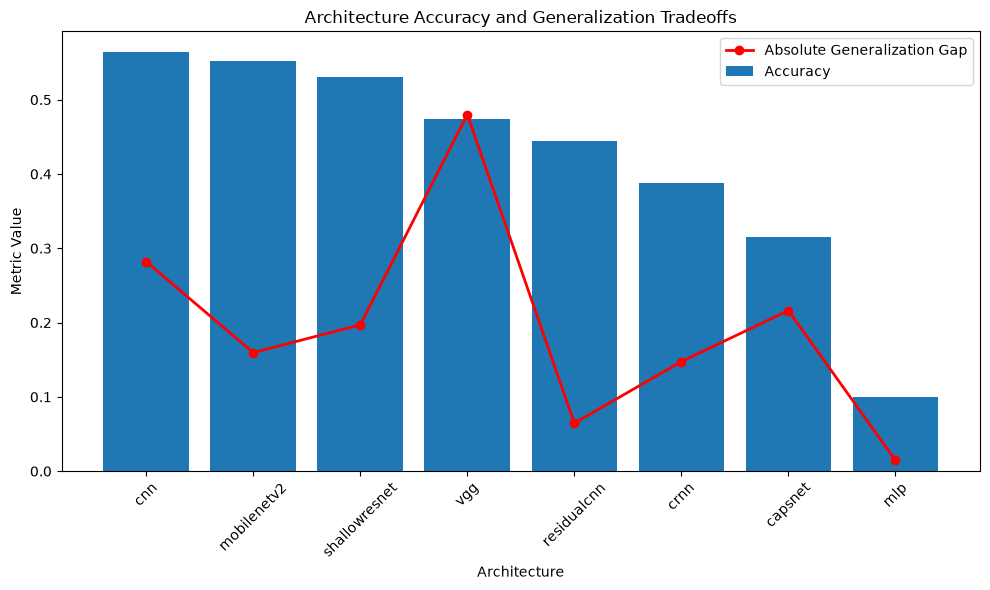

In [22]:
profile_df = (
    training_behavior_df[
        [
            "model",
            "mean_abs_gap"
        ]
    ]
    .merge(
        architecture_performance_df[
            [
                "model",
                "mean_accuracy"
            ]
        ],
        on="model"
    )
    .rename(
        columns={
            "mean_accuracy": "accuracy",
            "mean_abs_gap": "abs_gap"
        }
    )
    .sort_values(
        "accuracy",
        ascending=False
    )
)
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(profile_df))

ax.bar(
    x,
    profile_df["accuracy"],
    label="Accuracy"
)

ax.plot(
    x,
    profile_df["abs_gap"],
    color="red",
    marker="o",
    linewidth=2,
    label="Absolute Generalization Gap"
)

ax.set_xticks(x)
ax.set_xticklabels(
    profile_df["model"],
    rotation=45
)

ax.set_ylabel("Metric Value")
ax.set_xlabel("Architecture")

ax.set_title(
    "Architecture Accuracy and Generalization Tradeoffs"
)

ax.legend()

plt.tight_layout()
plt.show()

### Comments 
CNN achieved the highest overall classification accuracy (0.564), followed by MobileNetV2 (0.553) and ShallowResNet (0.530). However, increased predictive performance was often associated with larger generalization penalties. VGG exhibited the largest absolute generalization gap (0.480), whereas MLP achieved the smallest gap (0.015) but also produced the lowest overall accuracy (0.100). These results suggest a tradeoff between predictive performance and generalization robustness.


## Table 3. Overall Architecture Performance

In [23]:
architecture_performance_table = (
    architecture_performance_df[
        [
            "model",
            "mean_accuracy",
            "mean_test_f1",
            "mean_test_precision",
            "mean_test_recall",
            "parameters_million"
        ]
    ]
    .copy()
)

architecture_performance_table.columns = [
    "Architecture",
    "Accuracy",
    "F1",
    "Precision",
    "Recall",
    "Parameters (M)"
]

architecture_performance_table = (
    architecture_performance_table
    .sort_values(
        "Accuracy",
        ascending=False
    )
)

display_table(
    architecture_performance_table
)

Architecture,Accuracy,F1,Precision,Recall,Parameters (M)
cnn,0.5638,0.5590,0.5797,0.5638,3.3059
mobilenetv2,0.5522,0.5455,0.5533,0.5522,2.5885
shallowresnet,0.5307,0.4890,0.5825,0.5307,0.3272
vgg,0.4745,0.4251,0.5170,0.4745,0.3066
residualcnn,0.4442,0.3855,0.4666,0.4442,0.4825
crnn,0.3877,0.3145,0.3825,0.3877,0.1895
capsnet,0.3147,0.2707,0.3498,0.3147,0.2462
mlp,0.1000,0.0188,0.0105,0.1000,3.1486


### Comments 
CNN delivered the strongest overall classification performance, with MobileNetV2 and ShallowResNet remaining competitive across evaluation metrics. The performance differences observed in this table establish the basis for subsequent analyses of efficiency, duration sensitivity, and generalization behavior. No single architecture dominated every performance criterion.


## Figure 2. Test Accuracy Distribution by Architecture and Seed

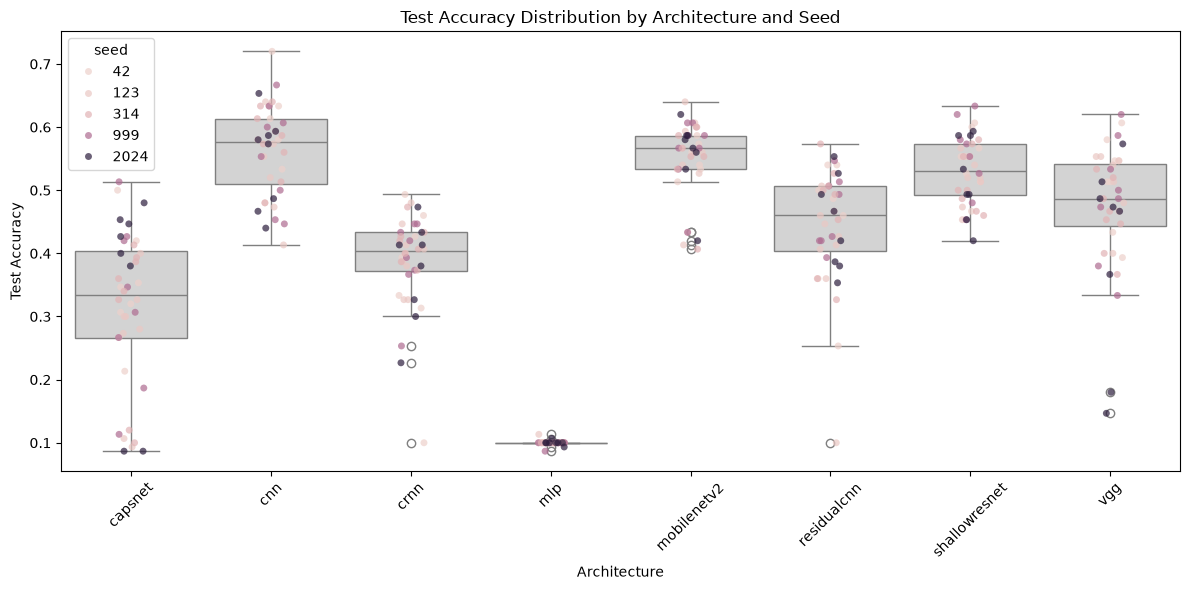

In [24]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=run_summaries_df,
    x="model",
    y="test_accuracy",
    color="lightgray"
)

sns.stripplot(
    data=run_summaries_df,
    x="model",
    y="test_accuracy",
    hue="seed",
    dodge=False,
    alpha=0.7,
    size=5
)

plt.ylabel("Test Accuracy")
plt.xlabel("Architecture")

plt.title(
    "Test Accuracy Distribution by Architecture and Seed"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Comments 
Accuracy distributions varied substantially across architectures. Some architectures demonstrated consistently strong performance across durations and random seeds, whereas others exhibited greater variability. The spread of each distribution provides insight into model stability not visible from mean accuracy alone.


## Table 4. Model Efficiency Ranking

In [25]:
model_efficiency_table = (
    model_efficiency_df[
        [
            "model",
            "params_million",
            "mean_accuracy",
            "mean_accuracy_per_million",
            "mean_training_seconds"
        ]
    ]
    .copy()
)

model_efficiency_table.columns = [
    "Architecture",
    "Parameters (M)",
    "Accuracy",
    "Accuracy / Million Params",
    "Training Seconds"
]

display_table(
    model_efficiency_table
)

Architecture,Parameters (M),Accuracy,Accuracy / Million Params,Training Seconds
capsnet,0.2462,0.3147,1.2783,228.2420
cnn,3.3059,0.5638,0.1706,161.9813
crnn,0.1895,0.3877,2.0463,33.0716
mlp,3.1486,0.1000,0.0318,7.9751
mobilenetv2,2.5885,0.5522,0.2133,235.0999
residualcnn,0.4825,0.4442,0.9205,314.9822
shallowresnet,0.3272,0.5307,1.6220,268.7524
vgg,0.3066,0.4745,1.5476,783.0295


### Comments
Efficiency analysis reveals predictive performance and computational cost are not perfectly aligned. CRNN achieved the highest accuracy-per-parameter ratio (2.046), indicating relatively compact architectures can remain highly competitive. These findings suggest parameter count alone is not a reliable predictor of classification success.


## Figure 3. Generalization Gap by Architecture

Text(0.5, 1.0, 'Generalization Gap by Architecture')

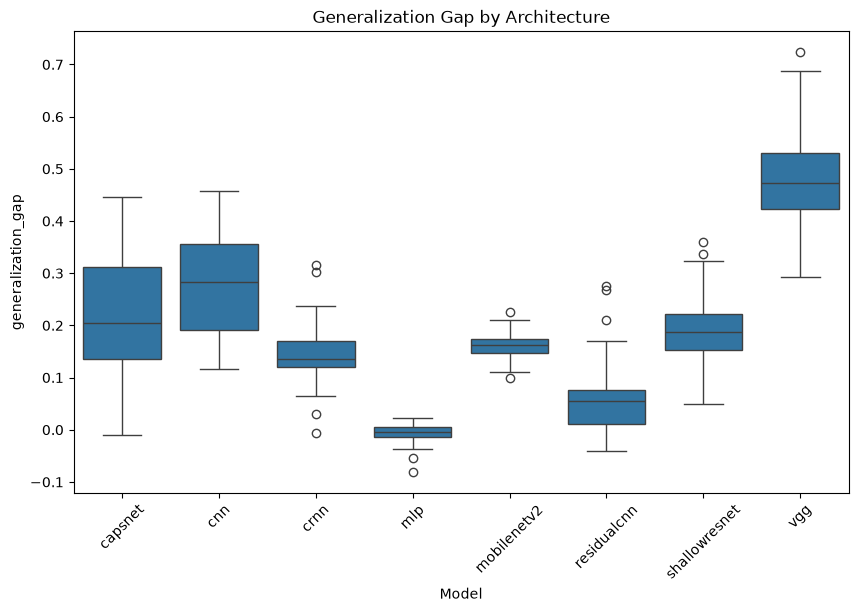

In [26]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=run_summaries_df,
    x="model",
    y="generalization_gap"
)

plt.xlabel("Generalization Gap")
plt.xlabel("Model")

plt.xticks(rotation=45)
plt.title("Generalization Gap by Architecture")

### Comments 
Generalization behavior varied considerably among architectures. MLP exhibited the smallest absolute generalization gap, while VGG exhibited the largest. The spread within each architecture's distribution indicates some models were consistently robust, whereas others showed substantial sensitivity to training conditions.


## Table 5. Training Behavior Summary

In [27]:
training_behavior_table = (
    training_behavior_df
    .copy()
)

training_behavior_table.columns = [
    "Architecture",
    "Avg Best Epoch",
    "Convergence Speed",
    "Training Seconds",
    "Training Accuracy Gain",
    "Generalization Gap",
    "Absolute Gap",
    "Overfitting Rate"
]


display_table(
    training_behavior_table
)

Architecture,Avg Best Epoch,Convergence Speed,Training Seconds,Training Accuracy Gain,Generalization Gap,Absolute Gap,Overfitting Rate
capsnet,24.2000,0.8107,228.2420,0.2538,0.2157,0.2162,0.5000
cnn,25.5250,0.8508,161.9813,0.4475,0.2819,0.2819,0.7250
crnn,29.1500,0.9725,33.0716,0.2702,0.1472,0.1476,0.1750
mlp,5.7000,0.2083,7.9751,0.0298,-0.0073,0.0145,0.0000
mobilenetv2,23.0250,0.7678,235.0999,0.3363,0.1597,0.1597,0.1000
residualcnn,28.8000,0.9604,314.9822,0.3212,0.0584,0.0646,0.0750
shallowresnet,29.2250,0.9742,268.7524,0.4022,0.1969,0.1969,0.3750
vgg,28.0000,0.9347,783.0295,0.3327,0.4800,0.4800,1.0000


### Comments
MLP achieved both the smallest absolute generalization gap (0.015) and a zero overfitting rate. In contrast, VGG produced the largest absolute gap (0.480) and overfit in every experimental run. CNN achieved the highest performance but incurred a substantially larger generalization penalty (0.282), illustrating a tradeoff between accuracy and robustness.


## Figure 4. Architecture Efficiency Landscape

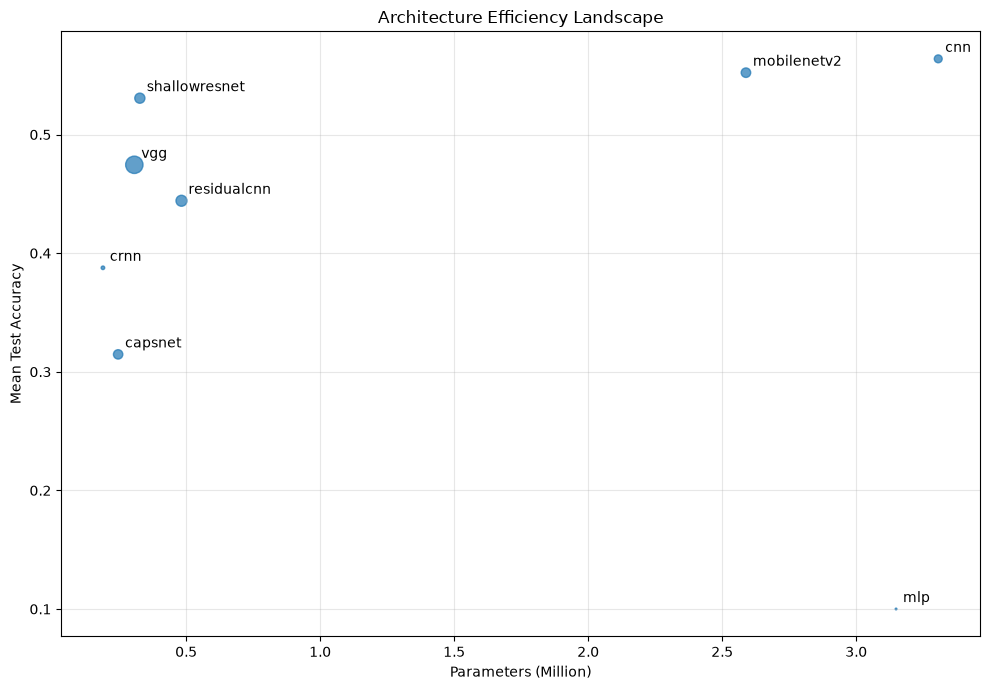

In [28]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    model_efficiency_df["params_million"],
    model_efficiency_df["mean_accuracy"],
    s=model_efficiency_df["mean_training_seconds"] / 5,
    alpha=0.7
)

for _, row in model_efficiency_df.iterrows():
    plt.annotate(
        row["model"],
        (
            row["params_million"],
            row["mean_accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Parameters (Million)")
plt.ylabel("Mean Test Accuracy")

plt.title(
    "Architecture Efficiency Landscape"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Comments
The efficiency landscape illustrates the relationship among predictive performance, model size, and training cost. CRNN occupies a favorable position because it combines competitive accuracy with a small parameter count. In contrast, several larger architectures achieved higher accuracy but required substantially greater computational resources.

# 4. Duration Effects

## Figure 5. Accuracy as a Function of Audio Duration

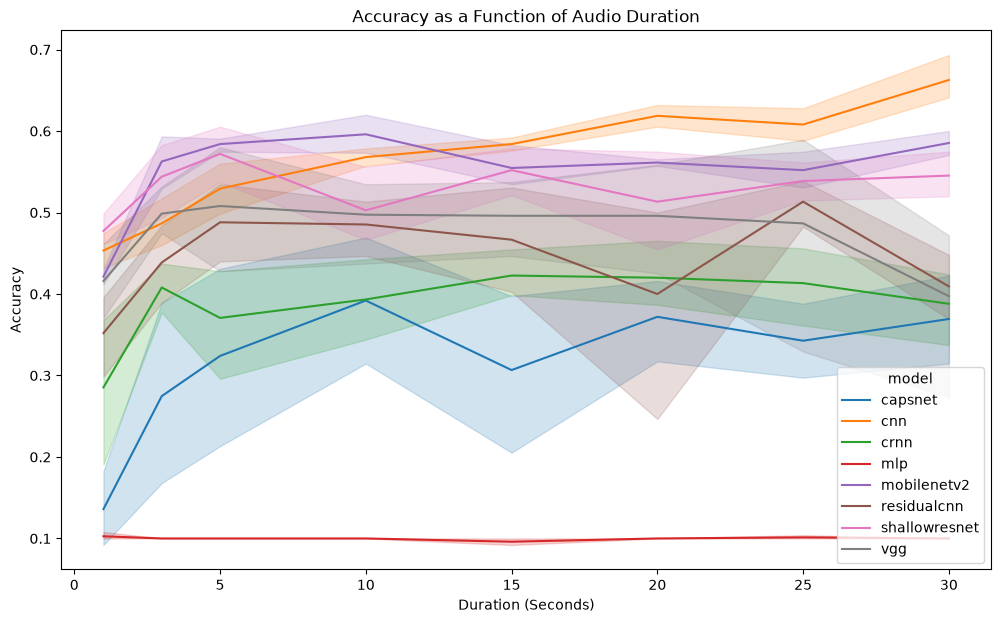

In [29]:
plt.figure(figsize=(12,7))

sns.lineplot(
    data=run_summaries_df,
    x="duration_seconds",
    y="test_accuracy",
    hue="model",
    estimator="mean",
    errorbar=("ci",95)
)

plt.ylabel("Accuracy")
plt.xlabel("Duration (Seconds)")

plt.title(
    "Accuracy as a Function of Audio Duration"
)

plt.show()

### Comments
Mean classification accuracy generally increased as audio duration increased from 1 to 30 seconds. The most substantial improvements occurred between shorter durations, after which gains became progressively smaller. This pattern suggests much of the information required for genre discrimination becomes available within the first several seconds of audio.


## Figure 6. Accuracy Gain by Duration Increment

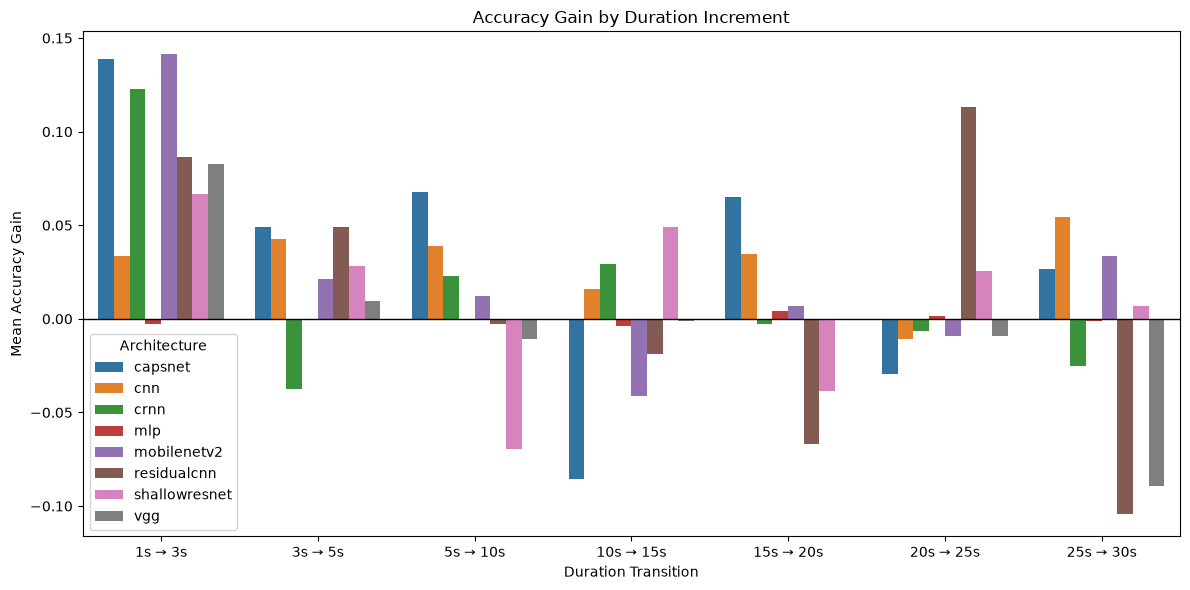

In [60]:
duration_pairwise_df["End Duration"] = (
    duration_pairwise_df["Comparison"]
    .str.extract(
        r"→\s*(\d+)s"
    )
    .astype(int)
)
plt.figure(
    figsize=(12, 6)
)

sns.barplot(
    data=duration_pairwise_df,
    x="Comparison",
    y="Mean Gain",
    hue="Architecture"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Accuracy Gain by Duration Increment"
)

plt.xlabel(
    "Duration Transition"
)

plt.ylabel(
    "Mean Accuracy Gain"
)

plt.tight_layout()

plt.show()

### Comments
Across multiple architectures, the majority of predictive benefit was obtained within the first several seconds of audio. Although longer excerpts often improved performance, the magnitude of improvement decreased as duration increased, providing evidence of a non-linear relationship characterized by diminishing returns.

## Table 6. Duration Performance Summary

In [30]:
duration_performance_table = (
    duration_performance_df[
        [
            "duration_seconds",
            "mean_accuracy",
            "mean_f1",
            "mean_precision",
            "mean_recall",
            "accuracy_ci95_lower",
            "accuracy_ci95_upper"
        ]
    ]
    .copy()
)

duration_performance_table.columns = [
    "Duration (s)",
    "Accuracy",
    "F1",
    "Precision",
    "Recall",
    "CI Lower",
    "CI Upper"
]

display_table(
    duration_performance_table
)

Duration (s),Accuracy,F1,Precision,Recall,CI Lower,CI Upper
1,0.3305,0.2851,0.3169,0.3305,0.2853,0.3757
3,0.4142,0.3665,0.4211,0.4142,0.3647,0.4637
5,0.4345,0.3956,0.4561,0.4345,0.3819,0.4871
10,0.4418,0.3958,0.4569,0.4418,0.3935,0.4902
15,0.4348,0.3896,0.4499,0.4348,0.3840,0.4857
20,0.4352,0.3863,0.4305,0.4352,0.3834,0.4869
25,0.4445,0.3994,0.4520,0.4445,0.3929,0.4961
30,0.4322,0.3899,0.4585,0.4322,0.3785,0.4859


### Comments
Performance improvements were observed across nearly the entire duration range. Mean accuracy, recall, and F1 score all increased as additional clip length became available. These results provide descriptive evidence of longer excerpts improving genre classification performance.


## Figure 7. Test Accuracy by Audio Duration

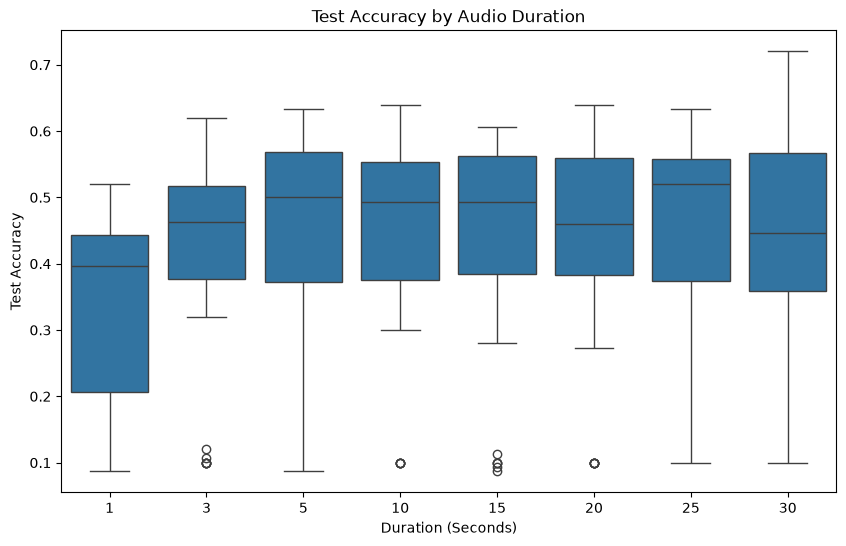

In [31]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=run_summaries_df,
    x="duration_seconds",
    y="test_accuracy"
)

plt.title(
    "Test Accuracy by Audio Duration"
)

plt.xlabel("Duration (Seconds)")
plt.ylabel("Test Accuracy")

plt.show()

### Comments
Accuracy distributions shifted upward as duration increased, indicating longer excerpts generally improved performance across architectures and seeds. Variability remained present at all durations, but the median and upper portions of the distributions consistently improved with increased clip length. This figure complements the mean trends reported in Table 6.


## Table 7. Duration Rankings

In [32]:
duration_rankings_table = (
    model_duration_rankings_df[
        [
            "duration_seconds",
            "model",
            "mean_accuracy",
            "mean_test_f1",
            "accuracy_rank",
            "f1_rank",
            "mean_rank"
        ]
    ]
    .copy()
)

duration_rankings_table.columns = [
    "Duration (s)",
    "Architecture",
    "Accuracy",
    "F1",
    "Accuracy Rank",
    "F1 Rank",
    "Composite Rank"
]

duration_rankings_table

,Duration (s),Architecture,Accuracy,F1,Accuracy Rank,F1 Rank,Composite Rank
0,1,cnn,0.453333,0.449950,2.0,1.0,1.5
1,1,shallowresnet,0.477333,0.431997,1.0,2.0,1.5
2,1,mobilenetv2,0.421333,0.413322,3.0,3.0,3.0
3,1,vgg,0.416000,0.365517,4.0,4.0,4.0
4,1,residualcnn,0.352000,0.304315,5.0,5.0,5.0
...,...,...,...,...,...,...,...
59,30,residualcnn,0.409333,0.359462,4.0,4.0,4.0
60,30,vgg,0.397333,0.332836,5.0,5.0,5.0
61,30,capsnet,0.369333,0.330123,7.0,6.0,6.5
62,30,crnn,0.388000,0.318353,6.0,7.0,6.5


### Comments
Architecture rankings were not constant across durations. Some architectures performed particularly well when shorter clips were used while others benefited substantially from longer excerpts. These ranking shifts demonstrate architecture selection and excerpt duration interact in meaningful ways.


## Table 8. Statistical Significance of Duration Effects

In [33]:
duration_significance_table[
    "Mean Accuracy Gain (%)"
] = (
    duration_significance_table[
        "Mean Accuracy Gain"
    ]
    * 100
)

duration_significance_table = (
    duration_significance_table[
        [
            "Architecture",
            "Mean Accuracy Gain (%)",
            "t Statistic",
            "p Value",
            "Cohen's d",
            "Significant (p < .05)"
        ]
    ]
)

display_table(duration_significance_table)

Architecture,Mean Accuracy Gain (%),t Statistic,p Value,Cohen's d,Significant (p < .05)
capsnet,23.3333,4.6077,0.0100,2.0606,True
cnn,20.9333,15.7791,0.0001,7.0566,True
mobilenetv2,16.4000,12.2088,0.0003,5.4599,True
crnn,10.2667,1.6228,0.1800,0.7257,False
shallowresnet,6.8000,3.4114,0.0270,1.5256,True
residualcnn,5.7333,1.4070,0.2322,0.6292,False
mlp,-0.2667,-1.0000,0.3739,-0.4472,False
vgg,-1.8667,-0.2321,0.8279,-0.1038,False


### Comments
Duration effects differed considerably among architectures. CapsNet (+23.3%), CNN (+20.9%), MobileNetV2 (+16.4%), and ShallowResNet (+6.8%) exhibited statistically supported improvements between 1-second and 30-second excerpts. CNN produced the largest observed effect size (Cohen's d = 7.06), while VGG and MLP showed no evidence of meaningful duration-related gains.


# 5. Genre-Level Analysis

## Figure 8. Genre Sensitivity to Additional Audio Duration

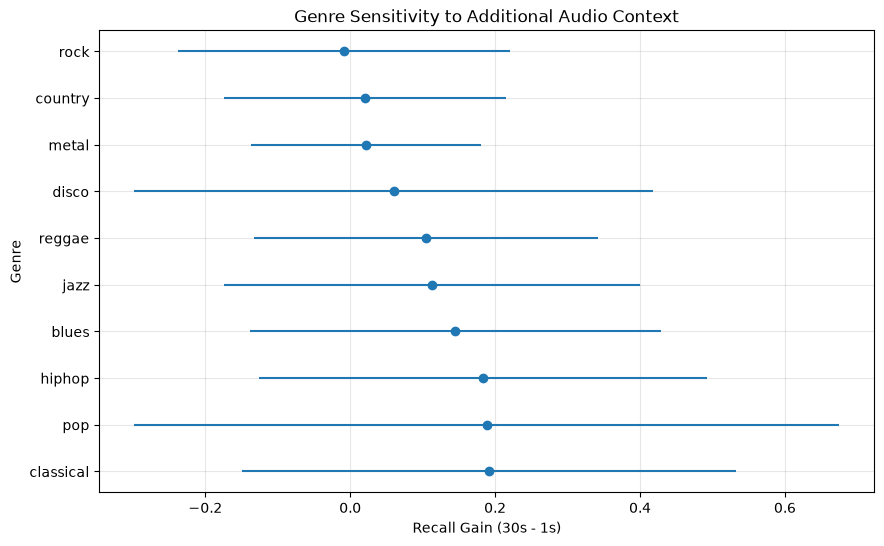

In [34]:
genre_plot = (
    duration_recall_gain_summary_df
    .groupby("genre")
    .agg(
        gain=("mean_gain", "mean"),
        lower=("lower_ci", "mean"),
        upper=("upper_ci", "mean")
    )
    .reset_index()
)

genre_plot = genre_plot.sort_values(
    "gain",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.errorbar(
    x=genre_plot["gain"],
    y=genre_plot["genre"],
    xerr=[
        genre_plot["gain"] - genre_plot["lower"],
        genre_plot["upper"] - genre_plot["gain"]
    ],
    fmt="o"
)

plt.xlabel(
    "Recall Gain (30s - 1s)"
)

plt.ylabel("Genre")

plt.title(
    "Genre Sensitivity to Additional Audio Context"
)

plt.grid(alpha=0.3)

plt.show()

### Comments
Relative recall gains differed substantially across genres. Blues, Reggae, Hip Hop, Jazz, Pop, and Classical exhibited large positive duration effects, while Rock displayed a slight decline in recall as duration increased. These differences indicate some genres are substantially more dependent on extended clip length than others.


## Table 9. Genre Duration Sensitivity and Best Architecture

In [35]:
genre_seed_recall = []

for (
    model,
    seed,
    duration,
    genre
), group in (
    confusion_matrix_long_df.groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )
):

    total = group["count"].sum()

    correct = (
        group.loc[
            group["actual"]
            == group["predicted"],
            "count"
        ]
        .sum()
    )

    recall = (
        correct / total
        if total > 0
        else np.nan
    )

    genre_seed_recall.append({
        "model": model,
        "seed": seed,
        "duration": duration,
        "genre": genre,
        "recall": recall
    })

genre_seed_recall_df = pd.DataFrame(
    genre_seed_recall
)

# --------------------------------------------------
# Compute genre-level gains and confidence intervals
# --------------------------------------------------

research_records = []

for genre, group in (
    genre_seed_recall_df.groupby("genre")
):

    recall_1s = (
        group[
            group["duration"] == 1
        ]
        .sort_values(
            ["model", "seed"]
        )["recall"]
    )

    recall_30s = (
        group[
            group["duration"] == 30
        ]
        .sort_values(
            ["model", "seed"]
        )["recall"]
    )

    gains = (
        recall_30s.values
        - recall_1s.values
    )

    mean_gain = gains.mean()

    n = len(gains)
    std_gain = gains.std(ddof=1)

    sem = std_gain / np.sqrt(n)

    ci95 = (
        t.ppf(
            0.975,
            df=n - 1
        )
        * sem
    )

    recall_1_mean = recall_1s.mean()
    recall_30_mean = recall_30s.mean()

    relative_gain = (
        100
        * (
            recall_30_mean
            - recall_1_mean
        )
        / recall_1_mean
    )

    ci_lower = mean_gain - ci95
    ci_upper = mean_gain + ci95

    research_records.append({
        "Genre": genre,
        "Recall @ 1s": recall_1_mean,
        "Recall @ 30s": recall_30_mean,
        "Recall Gain": mean_gain,
        "Relative Recall Gain (%)": relative_gain,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Significant": (
            "Yes"
            if ci_lower > 0
            else "No"
        )
    })

gain_stats_df = pd.DataFrame(
    research_records
)

# --------------------------------------------------
# Best architecture for each genre
# --------------------------------------------------

best_architecture_df = (
    genre_recall_by_model_df
    .sort_values(
        "recall",
        ascending=False
    )
    .groupby("genre")
    .first()
    .reset_index()
)

best_architecture_df = (
    best_architecture_df[
        [
            "genre",
            "model",
            "recall"
        ]
    ]
)

best_architecture_df.columns = [
    "Genre",
    "Best Architecture",
    "Best Recall"
]

# --------------------------------------------------
# Final research question table
# --------------------------------------------------

research_question_table = (
    gain_stats_df
    .merge(
        best_architecture_df,
        on="Genre"
    )
    .sort_values(
        "Relative Recall Gain (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

research_question_table = (
    research_question_table[
        [
            "Genre",
            "Recall @ 1s",
            "Recall @ 30s",
            "Recall Gain",
            "Relative Recall Gain (%)",
            "95% CI Lower",
            "95% CI Upper",
            "Significant",
            "Best Architecture",
            "Best Recall"
        ]
    ]
)

display_table(research_question_table)

Genre,Recall @ 1s,Recall @ 30s,Recall Gain,Relative Recall Gain (%),95% CI Lower,95% CI Upper,Significant,Best Architecture,Best Recall
blues,0.1767,0.3217,0.1450,82.0755,0.0350,0.2550,Yes,cnn,0.5600
reggae,0.2017,0.3067,0.1050,52.0661,0.0236,0.1864,Yes,cnn,0.5267
hiphop,0.4183,0.6017,0.1833,43.8247,0.0782,0.2884,Yes,shallowresnet,0.7533
jazz,0.2683,0.3817,0.1133,42.2360,0.0191,0.2076,Yes,shallowresnet,0.6650
pop,0.4700,0.6583,0.1883,40.0709,0.0422,0.3345,Yes,vgg,0.7383
classical,0.5450,0.7367,0.1917,35.1682,0.0690,0.3143,Yes,cnn,0.9133
disco,0.2683,0.3283,0.0600,22.3602,-0.0566,0.1766,No,capsnet,0.5150
country,0.2133,0.2333,0.0200,9.3750,-0.0608,0.1008,No,mobilenetv2,0.5183
metal,0.6017,0.6233,0.0217,3.6011,-0.0353,0.0787,No,crnn,0.9717
rock,0.1383,0.1300,-0.0083,-6.0241,-0.0871,0.0704,No,cnn,0.3033


### Comments
Blues exhibited the largest relative recall improvement, increasing from 0.177 to 0.322 recall and producing an 82.1% relative gain. Classical achieved the largest absolute gain (+0.192), while Hip Hop (+0.183) and Pop (+0.188) also improved substantially. Rock showed a slight decline in recall (-6.0%) and no statistically supported duration effect.


## Figure 9. Genre Recall Profile by Architecture

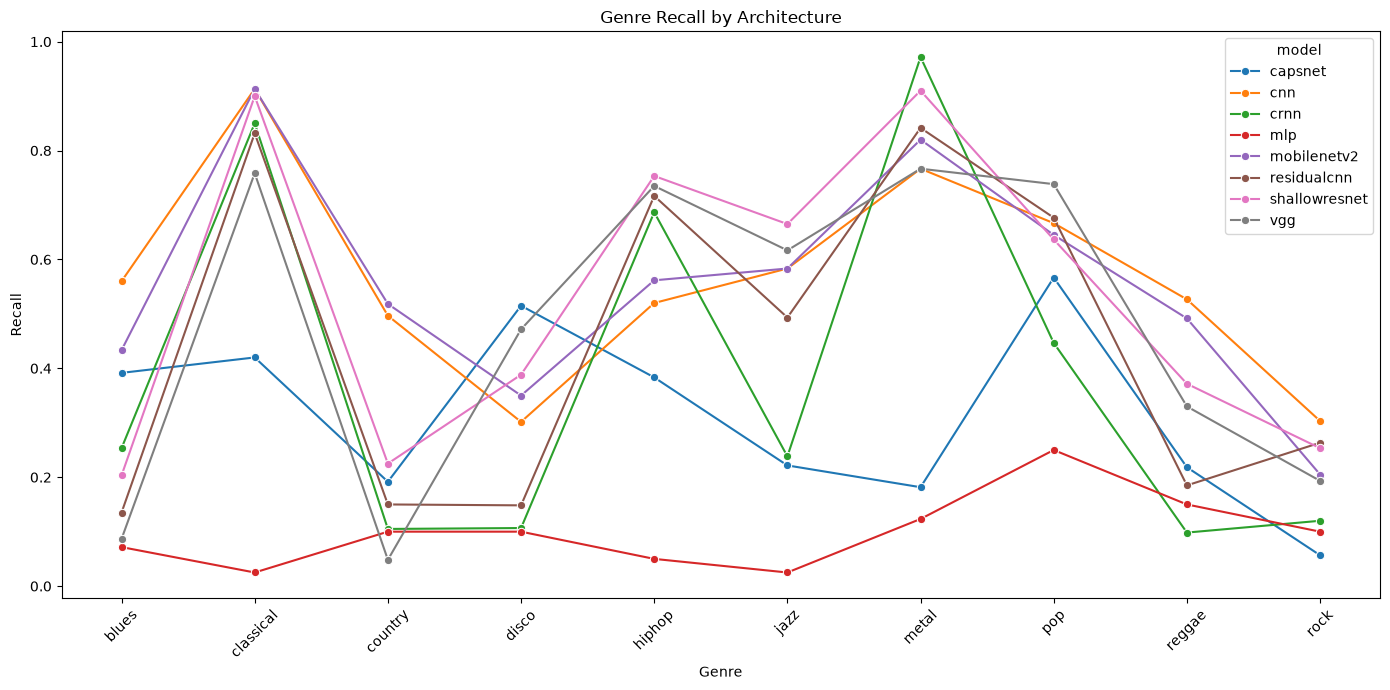

In [36]:
plt.figure(figsize=(14, 7))

genre_means = (
    genre_duration_recall_df
    .groupby(
        ["genre", "model"]
    )["recall"]
    .mean()
    .reset_index()
)

sns.lineplot(
    data=genre_means,
    x="genre",
    y="recall",
    hue="model",
    marker="o"
)

plt.title(
    "Genre Recall by Architecture"
)

plt.xlabel("Genre")
plt.ylabel("Recall")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Comments
Genre performance varied considerably across architectures. No single architecture consistently achieved the highest recall for every genre, indicating different architectural designs capture different musical characteristics. Several architectures with clear genre-specific strengths are explored further in Table 10.

## Table 10. Genre Recall Summary by Architecture

In [37]:
genre_recall_summary_table = (
    genre_recall_by_model_df
    .pivot(
        index="genre",
        columns="model",
        values="recall"
    )
    .round(3)
)

display_table(genre_recall_summary_table)

capsnet,cnn,crnn,mlp,mobilenetv2,residualcnn,shallowresnet,vgg
0.3920,0.5600,0.2530,0.0720,0.4330,0.1350,0.2030,0.0870
0.4200,0.9130,0.8500,0.0250,0.9130,0.8320,0.9000,0.7580
0.1920,0.4970,0.1050,0.1000,0.5180,0.1500,0.2250,0.0480
0.5150,0.3020,0.1070,0.1000,0.3500,0.1480,0.3880,0.4720
0.3830,0.5200,0.6870,0.0500,0.5620,0.7170,0.7530,0.7350
0.2220,0.5830,0.2380,0.0250,0.5830,0.4930,0.6650,0.6170
0.1820,0.7670,0.9720,0.1230,0.8200,0.8420,0.9100,0.7670
0.5670,0.6670,0.4470,0.2500,0.6450,0.6770,0.6370,0.7380
0.2180,0.5270,0.0980,0.1500,0.4920,0.1850,0.3720,0.3300
0.0570,0.3030,0.1200,0.1000,0.2050,0.2630,0.2530,0.1930


### Comments
Architecture performance depended strongly on genre. CNN achieved the highest recall for several genres, while other architectures emerged as specialists for specific categories. These results reinforce the finding overall performance rankings do not fully capture genre-specific behavior.


## Table 11. Average Genre Recall Ranking

In [38]:
genre_recall_ranking_table = (
    genre_recall_by_model_df
    .groupby("genre")["recall"]
    .agg(
        mean_recall="mean",
        std_recall="std",
        min_recall="min",
        max_recall="max"
    )
    .reset_index()
    .sort_values(
        "mean_recall",
        ascending=False
    )
)

display_table(
    genre_recall_ranking_table
)

genre,mean_recall,std_recall,min_recall,max_recall
classical,0.7015,0.3181,0.0250,0.9133
metal,0.6727,0.3287,0.1233,0.9717
pop,0.5783,0.1587,0.2500,0.7383
hiphop,0.5508,0.2393,0.0500,0.7533
jazz,0.4283,0.2346,0.0250,0.6650
disco,0.2977,0.1632,0.1000,0.5150
reggae,0.2965,0.1591,0.0983,0.5267
blues,0.2669,0.1778,0.0717,0.5600
country,0.2294,0.1803,0.0483,0.5183
rock,0.1869,0.0872,0.0567,0.3033


### Comments
Architecture performance depended strongly on genre. CNN achieved the highest recall for several genres, while other architectures emerged as specialists for specific categories. These results reinforce the finding overall performance rankings do not fully capture genre-specific behavior.


## Table 12. Average Genre Recall Ranking

In [39]:
genre_duration_recall_table = (
    genre_duration_recall_df
    .pivot_table(
        index="genre",
        columns="duration",
        values="recall",
        aggfunc="mean"
    )
    .round(3)
)

display_table(genre_duration_recall_table)

1,3,5,10,15,20,25,30
0.1770,0.2220,0.2650,0.2700,0.2880,0.2820,0.3100,0.3220
0.5450,0.6950,0.7250,0.7320,0.6970,0.7130,0.7680,0.7370
0.2130,0.2520,0.2420,0.2070,0.2580,0.2120,0.2180,0.2330
0.2680,0.2500,0.3000,0.3000,0.2880,0.3030,0.3430,0.3280
0.4180,0.5180,0.5270,0.6150,0.5470,0.6220,0.5580,0.6020
0.2680,0.4370,0.4620,0.4680,0.4900,0.4270,0.4930,0.3820
0.6020,0.7280,0.7000,0.7470,0.6770,0.6180,0.6870,0.6230
0.4700,0.5730,0.5850,0.5620,0.6020,0.6120,0.5650,0.6580
0.2020,0.3280,0.3730,0.3050,0.2500,0.3050,0.3020,0.3070
0.1380,0.1380,0.1670,0.2130,0.2520,0.2580,0.1980,0.1300


### Comments
Classification difficulty varied substantially across genres. Some genres achieved consistently high recall across architectures, whereas others remained difficult regardless of model choice. These rankings provide a broad summary of genre-level classification challenges present within the dataset.


## Table 13. Genre Improvement Summary

In [40]:
genre_improvement_table = (
    genre_duration_recall_df
    .groupby(
        ["genre", "duration"]
    )["recall"]
    .mean()
    .reset_index()
    .pivot(
        index="genre",
        columns="duration",
        values="recall"
    )
)

genre_improvement_table["gain_1s_to_30s"] = (
    genre_improvement_table[30]
    - genre_improvement_table[1]
)

genre_improvement_table = (
    genre_improvement_table
    .sort_values(
        "gain_1s_to_30s",
        ascending=False
    )
)

genre_improvement_table

duration,1,3,5,10,15,20,25,30,gain_1s_to_30s
genre,,,,,,,,,
classical,0.545000,0.695000,0.725000,0.731667,0.696667,0.713333,0.768333,0.736667,0.191667
pop,0.470000,0.573333,0.585000,0.561667,0.601667,0.611667,0.565000,0.658333,0.188333
hiphop,0.418333,0.518333,0.526667,0.615000,0.546667,0.621667,0.558333,0.601667,0.183333
blues,0.176667,0.221667,0.265000,0.270000,0.288333,0.281667,0.310000,0.321667,0.145000
jazz,0.268333,0.436667,0.461667,0.468333,0.490000,0.426667,0.493333,0.381667,0.113333
reggae,0.201667,0.328333,0.373333,0.305000,0.250000,0.305000,0.301667,0.306667,0.105000
disco,0.268333,0.250000,0.300000,0.300000,0.288333,0.303333,0.343333,0.328333,0.060000
metal,0.601667,0.728333,0.700000,0.746667,0.676667,0.618333,0.686667,0.623333,0.021667
country,0.213333,0.251667,0.241667,0.206667,0.258333,0.211667,0.218333,0.233333,0.020000


### Comments
Relative improvements were often largest for genres with low initial recall. Blues improved by more than 80% relative to its 1-second baseline, while Rock exhibited a slight decline. This pattern suggests longer excerpts may be especially beneficial for genres difficult to recognize from short segments.


## Figure 10. Genre Recall by Architecture Across Duration

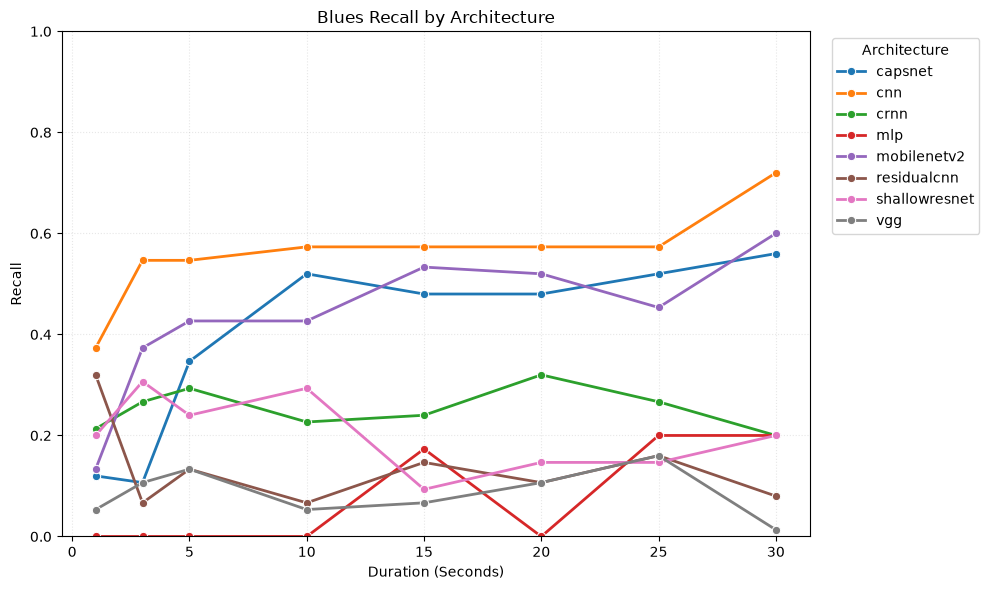

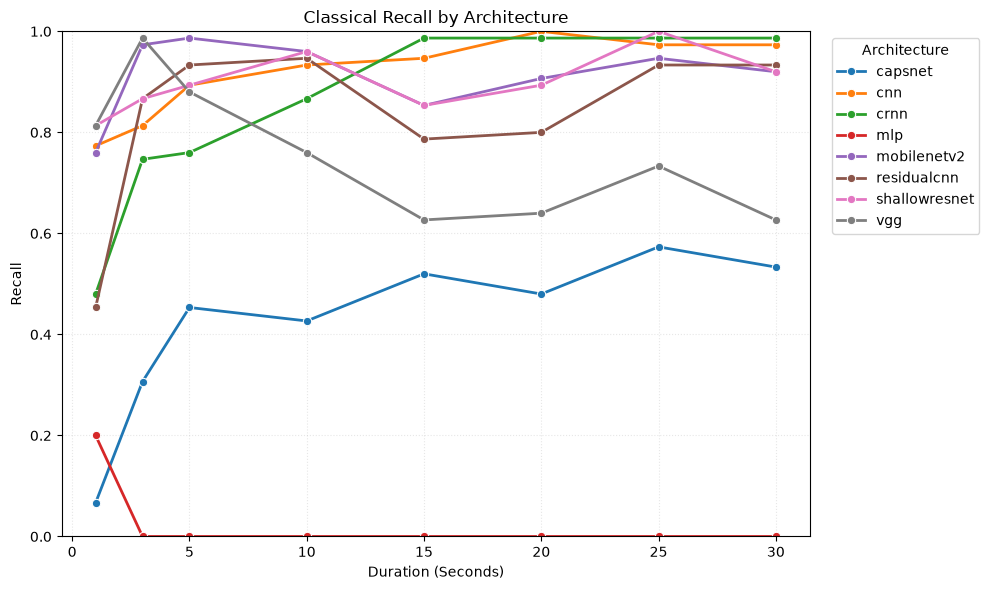

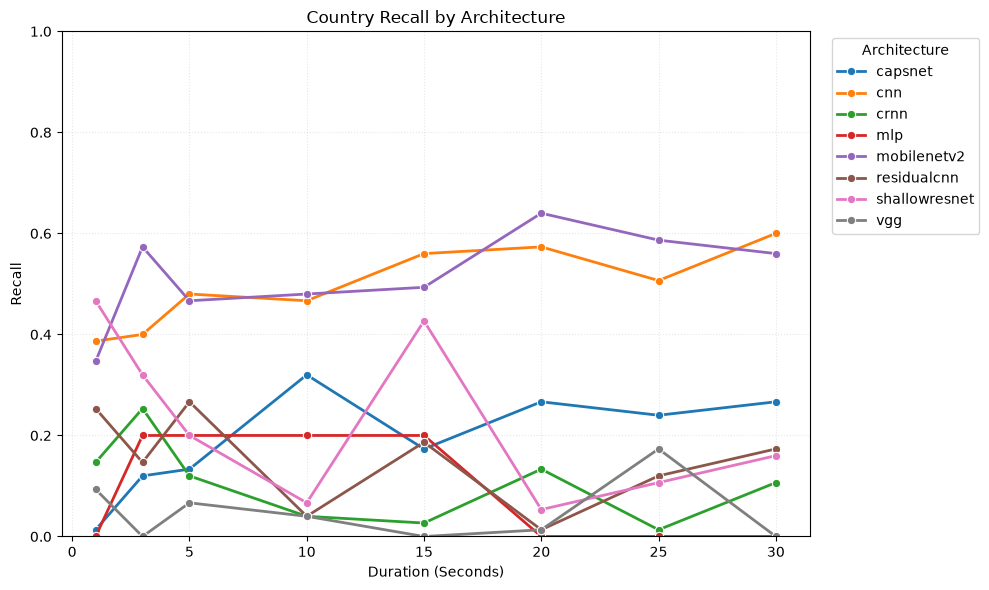

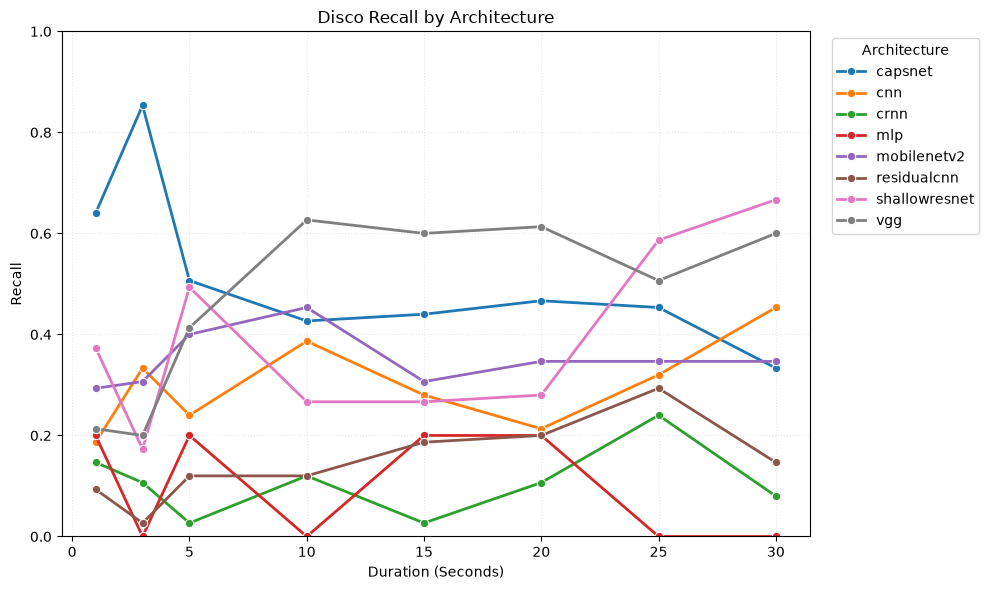

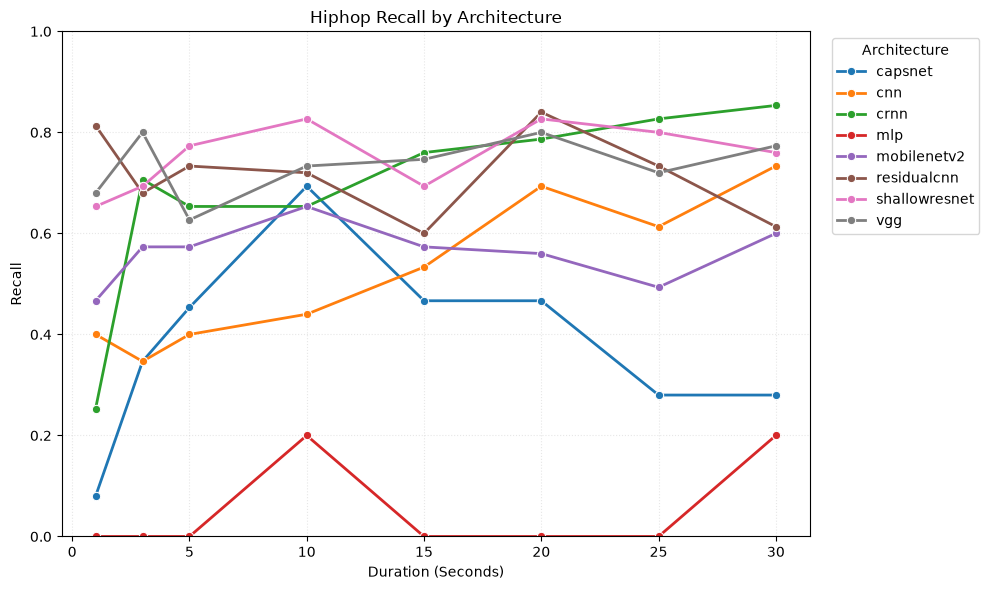

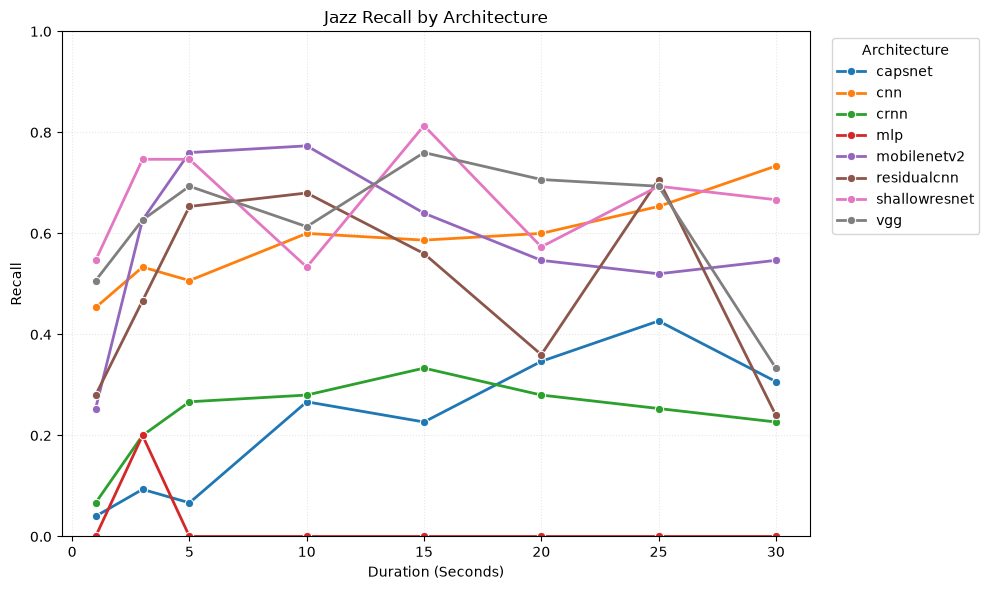

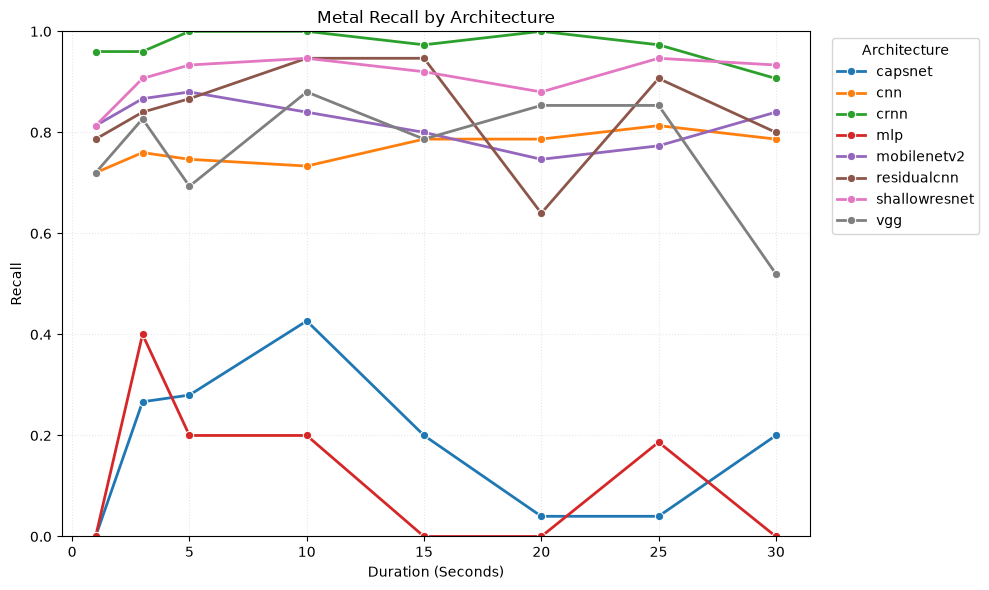

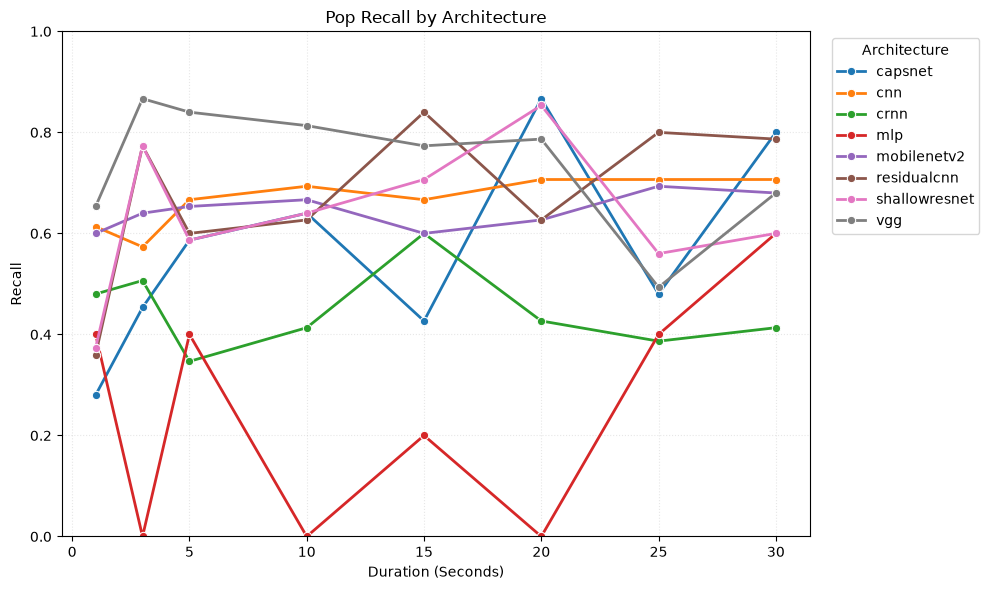

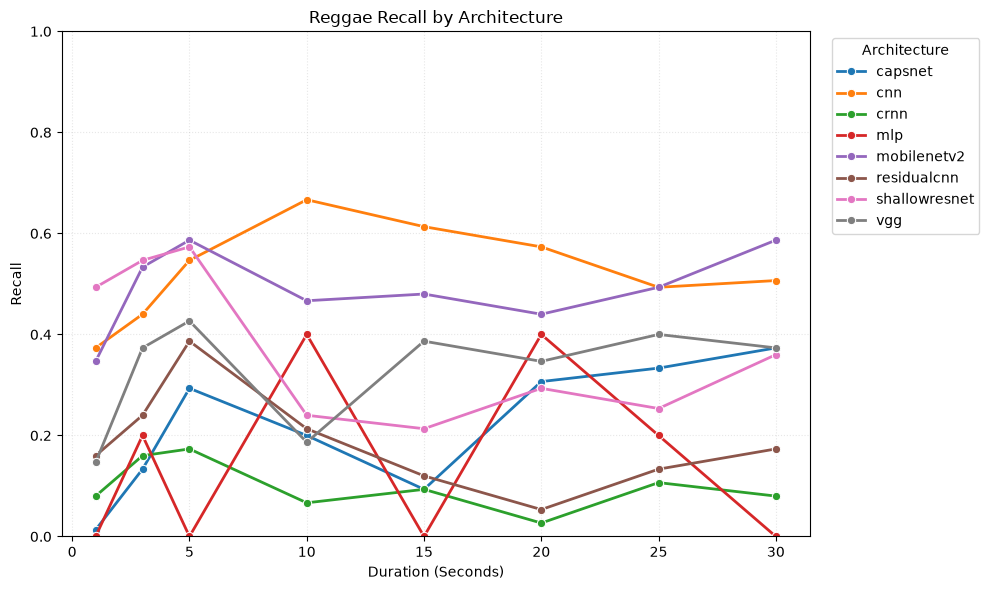

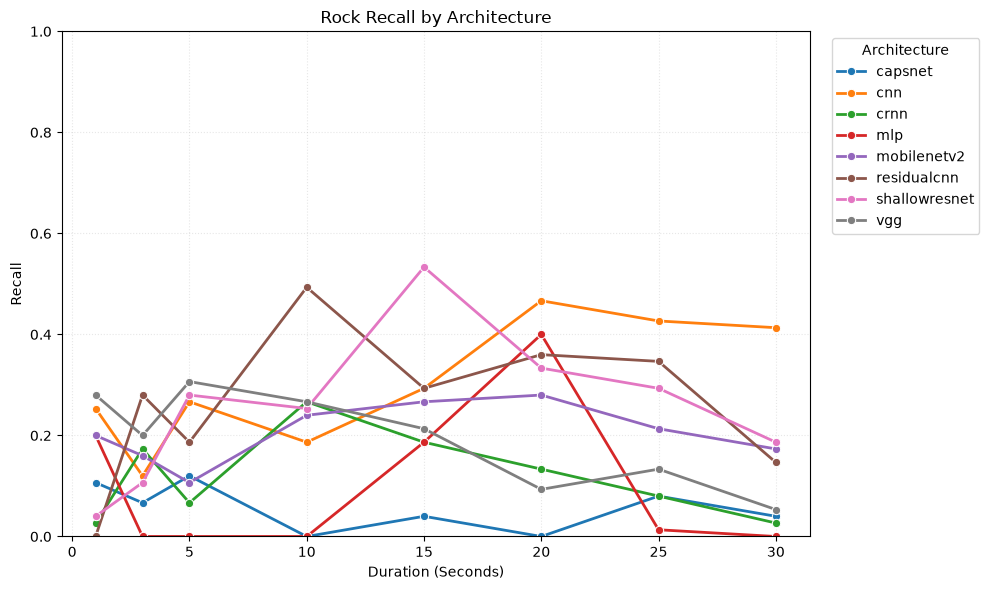

In [41]:
genres = sorted(
    genre_duration_recall_df["genre"].unique()
)

for genre in genres:

    plt.figure(figsize=(10, 6))

    subset = (
        genre_duration_recall_df[
            genre_duration_recall_df["genre"] == genre
        ]
    )

    sns.lineplot(
        data=subset,
        x="duration",
        y="recall",
        hue="model",
        marker="o",
        linewidth=2
    )

    plt.title(
        f"{genre.title()} Recall by Architecture"
    )

    plt.xlabel("Duration (Seconds)")
    plt.ylabel("Recall")

    plt.ylim(0, 1)

    plt.grid(
        alpha=0.3,
        linestyle=":"
    )

    plt.legend(
        title="Architecture",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

### Comments
Genre-specific duration trajectories reveal substantial variation in how architectures respond to clip length. Some architecture-genre combinations exhibit rapid improvements with increasing duration, while others remain largely unchanged. These plots provide the most detailed view of duration effects at the individual genre level.


# 6. Error Analysis

## Table 14. Most Common Genre Confusions

In [42]:
aggregate_genre_confusions_table = (
    genre_confusion_summary_df
    .groupby(
        ["actual", "predicted"]
    )
    .agg(
        total_count=("count", "sum"),
        mean_confusion_rate=("confusion_rate", "mean")
    )
    .reset_index()
)

aggregate_genre_confusions_table = (
    aggregate_genre_confusions_table[
        aggregate_genre_confusions_table["actual"]
        != aggregate_genre_confusions_table["predicted"]
    ]
)

aggregate_genre_confusions_table["confusion_percent"] = (
    aggregate_genre_confusions_table["mean_confusion_rate"]
    * 100
)

aggregate_genre_confusions_table = (
    aggregate_genre_confusions_table[
        [
            "actual",
            "predicted",
            "total_count",
            "confusion_percent"
        ]
    ]
    .sort_values(
        [
            "confusion_percent",
            "total_count"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

aggregate_genre_confusions_table.columns = [
    "Actual Genre",
    "Predicted Genre",
    "Total Misclassifications",
    "Confusion (%)"
]

display_table(
    aggregate_genre_confusions_table.head(20)
)

Actual Genre,Predicted Genre,Total Misclassifications,Confusion (%)
reggae,hiphop,1203,25.0625
rock,disco,849,17.6875
blues,disco,811,16.8958
disco,pop,789,16.4375
country,rock,770,16.0417
country,pop,735,15.3125
country,disco,693,14.4375
hiphop,pop,662,13.7917
disco,metal,649,13.5208
disco,hiphop,629,13.1042


### Comments
This table summarizes the most frequently observed genre confusions across all architectures, durations, and random seeds. Higher confusion percentages indicate genre pairs remained difficult to distinguish despite increased clip length. Persistent confusion patterns suggest overlapping acoustic characteristics were not fully resolved by architectural differences or longer audio excerpts.

# Figure 11. Most Common Genre Misclassifications

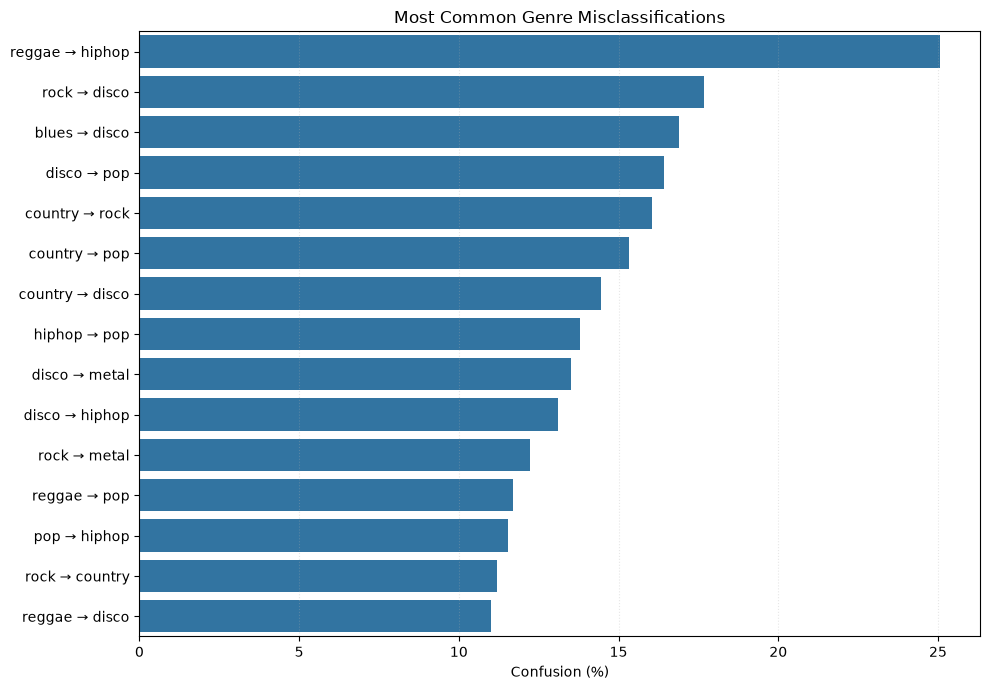

In [43]:
plot_df = (
    aggregate_genre_confusions_table
    .head(15)
    .copy()
)

plot_df["Confusion Pair"] = (
    plot_df["Actual Genre"]
    + " → "
    + plot_df["Predicted Genre"]
)

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.figure(figsize=(10, 7))

sns.barplot(
    data=plot_df,
    x="Confusion (%)",
    y="Confusion Pair",
    orient="h"
)

plt.title(
    "Most Common Genre Misclassifications"
)

plt.xlabel("Confusion (%)")
plt.ylabel("")

plt.grid(
    axis="x",
    alpha=0.3,
    linestyle=":"
)

plt.tight_layout()
plt.show()

# 7. Leaderboards

## Table 15. Generalization Behavior Summary

In [44]:
generalization_summary_table = (
    training_behavior_df[
        [
            "model",
            "mean_generalization_gap",
            "mean_abs_gap",
            "overfitting_rate"
        ]
    ]
    .copy()
)

generalization_summary_table.columns = [
    "Architecture",
    "Mean Gap",
    "Absolute Gap",
    "Overfitting Rate"
]

generalization_summary_table = (
    generalization_summary_table
    .sort_values(
        "Absolute Gap"
    )
    .reset_index(drop=True)
)

display_table(generalization_summary_table)

Architecture,Mean Gap,Absolute Gap,Overfitting Rate
mlp,-0.0073,0.0145,0.0000
residualcnn,0.0584,0.0646,0.0750
crnn,0.1472,0.1476,0.1750
mobilenetv2,0.1597,0.1597,0.1000
shallowresnet,0.1969,0.1969,0.3750
capsnet,0.2157,0.2162,0.5000
cnn,0.2819,0.2819,0.7250
vgg,0.4800,0.4800,1.0000


### Comments
Generalization behavior varied considerably across architectures. MLP achieved the smallest absolute generalization gap (0.015) and exhibited no overfitting across experimental runs. In contrast, VGG produced the largest absolute generalization gap (0.480) and an overfitting rate of 1.000, indicating evidence of overfitting in every run. CNN achieved the highest overall accuracy but incurred a substantially larger generalization penalty (0.282) than several competing architectures.

## Table 16. Architecture Leaderboard

In [45]:
# --------------------------------------------------
# Architecture leaders
# --------------------------------------------------

overall_winner = (
    architecture_performance_df
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

efficiency_winner = (
    model_efficiency_df
    .sort_values(
        "mean_accuracy_per_million",
        ascending=False
    )
    .iloc[0]
)

short_duration_winner = (
    architecture_duration_summary_df[
        architecture_duration_summary_df[
            "duration_seconds"
        ] == 1
    ]
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

long_duration_winner = (
    architecture_duration_summary_df[
        architecture_duration_summary_df[
            "duration_seconds"
        ] == 30
    ]
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

duration_gain_winner = (
    duration_significance_table
    .sort_values(
        "Mean Accuracy Gain (%)",
        ascending=False
    )
    .iloc[0]
)

genre_specialist = (
    genre_recall_by_model_df.loc[
        genre_recall_by_model_df["recall"].idxmax()
    ]
)

# --------------------------------------------------
# Generalization leaders
# --------------------------------------------------

lowest_gap = (
    training_behavior_df
    .sort_values("mean_abs_gap")
    .iloc[0]
)

highest_gap = (
    training_behavior_df
    .sort_values(
        "mean_abs_gap",
        ascending=False
    )
    .iloc[0]
)

lowest_overfit = (
    training_behavior_df
    .sort_values("overfitting_rate")
    .iloc[0]
)

highest_overfit = (
    training_behavior_df
    .sort_values(
        "overfitting_rate",
        ascending=False
    )
    .iloc[0]
)

leaderboard_table = pd.DataFrame([
    {
        "Category": "Overall Accuracy Leader",
        "Architecture": overall_winner["model"],
        "Value": f"{overall_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Most Parameter Efficient",
        "Architecture": efficiency_winner["model"],
        "Value": f"{efficiency_winner['mean_accuracy_per_million']:.3f}"
    },
    {
        "Category": "Best 1-Second Model",
        "Architecture": short_duration_winner["model"],
        "Value": f"{short_duration_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Best 30-Second Model",
        "Architecture": long_duration_winner["model"],
        "Value": f"{long_duration_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Largest Duration Gain",
        "Architecture": duration_gain_winner["Architecture"],
        "Value": (
            f"{duration_gain_winner['Mean Accuracy Gain (%)']:.1f}%"
        )
    },
    {
        "Category": "Best Genre Specialist",
        "Architecture": genre_specialist["model"],
        "Value": (
            f"{genre_specialist['genre']} "
            f"({genre_specialist['recall']:.3f})"
        )
    },
    {
        "Category": "Best Generalization",
        "Architecture": lowest_gap["model"],
        "Value": f"{lowest_gap['mean_abs_gap']:.3f}"
    },
    {
        "Category": "Lowest Overfitting Rate",
        "Architecture": lowest_overfit["model"],
        "Value": f"{lowest_overfit['overfitting_rate']:.3f}"
    },
    {
        "Category": "Weakest Generalization",
        "Architecture": highest_gap["model"],
        "Value": f"{highest_gap['mean_abs_gap']:.3f}"
    },
    {
        "Category": "Highest Overfitting Rate",
        "Architecture": highest_overfit["model"],
        "Value": f"{highest_overfit['overfitting_rate']:.3f}"
    }
])

display_table(leaderboard_table)

Category,Architecture,Value
Overall Accuracy Leader,cnn,0.564
Most Parameter Efficient,crnn,2.046
Best 1-Second Model,shallowresnet,0.477
Best 30-Second Model,cnn,0.663
Largest Duration Gain,capsnet,23.3%
Best Genre Specialist,crnn,metal (0.972)
Best Generalization,mlp,0.015
Lowest Overfitting Rate,mlp,0.000
Weakest Generalization,vgg,0.480
Highest Overfitting Rate,vgg,1.000


### Comments
No single architecture dominated every evaluation criterion. CNN achieved both the highest overall accuracy (0.564) and the strongest 30-second performance (0.663). CRNN achieved the highest parameter efficiency (2.046) and the strongest genre-specific result, reaching 0.972 recall for Metal. CapsNet exhibited the largest duration-driven improvement (+23.3%), while MLP demonstrated the strongest generalization characteristics and VGG exhibited the weakest.

# 8. Summary of Findings

### Audio Duration Improved Classification Performance... but Not Equally

Figure 5 and Table 6 show classification performance generally increased as additional audio clip length became available. However, Table 8 demonstrates  duration effects were not uniform across architectures. CapsNet exhibited the largest improvement between 1-second and 30-second excerpts (+23.3%), followed by CNN (+20.9%), MobileNetV2 (+16.4%), and ShallowResNet (+6.8%). These architectures also produced statistically significant gains and large effect sizes, indicating longer clip length provided both statistically and practically meaningful benefits.

### CNN Achieved the Strongest Overall Classification Performance

As shown in Figure 1 and Table 3, CNN achieved the highest overall mean classification accuracy (0.564) among all evaluated architectures. Table 15 further shows CNN also achieved the strongest performance on 30-second excerpts (0.663). These findings indicate CNN was particularly effective when sufficient clip length was available.

### Short and Long Excerpts Favored Different Architectures

Performance leadership varied across durations. Table 15 shows ShallowResNet achieved the highest accuracy on 1-second excerpts (0.477), whereas CNN achieved the highest accuracy on 30-second excerpts (0.663). Figure 7 and Table 7 reinforce this observation by showing architecture rankings shifted as audio duration increased, indicating architecture effectiveness depends partly on the amount of available clip duration.

### CRNN Provided the Best Accuracy-to-Complexity Tradeoff

Figure 4 and Table 4 demonstrate CRNN achieved the highest parameter efficiency, producing 2.046 units of accuracy per million parameters. Although CRNN did not achieve the highest overall classification accuracy, Table 15 shows it also achieved the strongest genre-specific performance in the study, reaching 0.972 recall on Metal recordings. These results suggest CRNN offered the most favorable balance between predictive performance and computational complexity.

### Duration Effects Varied Substantially Across Genres

Figure 8 and Table 9 reveal substantial variation in genre sensitivity to audio duration. Blues exhibited the largest relative improvement, increasing from 0.177 recall at 1 second to 0.322 recall at 30 seconds, representing an 82.1% relative gain. Classical achieved the largest absolute improvement (+0.192 recall), while Pop (+0.188) and Hip Hop (+0.183) also demonstrated substantial gains. These findings indicate some genres require substantially more clip length than others for reliable classification.

### Several Genres Showed Little Benefit from Longer Clip Length

Table 9 indicates not all genres benefited from longer excerpts. Metal improved only from 0.602 to 0.623 recall, Country improved from 0.213 to 0.233 recall, and Rock decreased slightly from 0.138 to 0.130 recall. Confidence intervals for these genres included zero, leading them to be classified as lacking statistically supported duration effects. These results suggest additional clip length is not universally beneficial for music genre recognition.

### Rock Remained Difficult Regardless of Duration

Figure 8 and Table 9 identify Rock as the only genre exhibiting a negative relative gain (-6.0%) when moving from 1-second to 30-second excerpts. Despite providing substantially more audio, classification performance did not improve. Figure 11 and Table 14 show persistent genre confusions remained common, suggesting classification difficulties for Rock are driven by overlap with neighboring genres rather than insufficient listening time.

### No Architecture Dominated Every Genre

Figure 9 and Table 10 demonstrate architecture performance varied on genre. Different architectures emerged as leaders for different musical styles, and no single architecture consistently achieved the highest recall across all genres. Table 15 further illustrates this specialization by showing CNN, CRNN, ShallowResNet, MobileNetV2, and CapsNet each achieved best-in-class results for particular genres or evaluation criteria.

### Generalization Characteristics Varied Widely Across Architectures

Figure 3 and Table 5 reveal substantial differences in generalization behavior. MLP achieved the smallest absolute generalization gap (0.015) and an overfitting rate of 0.000, indicating highly consistent behavior between training and evaluation data. In contrast, VGG produced the largest absolute generalization gap (0.480) and an overfitting rate of 1.000, indicating every VGG run exhibited overfitting. These findings demonstrate predictive performance and generalization quality represent distinct dimensions of model evaluation.

### Higher Accuracy Often Came With Greater Overfitting Risk

Figure 1 and Table 5 show CNN achieved the highest overall classification accuracy but also incurred a relatively large absolute generalization gap (0.282). Conversely, MLP exhibited excellent generalization but poor classification performance (0.100 accuracy). Together, these findings suggest  maximizing predictive performance frequently comes at the cost of increased overfitting risk.

### Classification Errors Followed Consistent Patterns

Figure 11 and Table 14 indicate several genre confusions persisted across architectures, durations, and experimental conditions. The recurrence of these misclassification patterns suggests some genre boundaries remain inherently difficult to separate using the available acoustic representations. Additional clip length reduced some errors but did not eliminate several of the most persistent confusion pairs.

## Noted Conclusions

Taken together, the evidence presented in Figures 1 through 10 and Tables 1 through 15 demonstrates audio duration is an important but genre-dependent and architecture-dependent factor in music genre classification. CNN achieved the strongest overall performance (Table 3; Table 15), CRNN delivered the best efficiency-to-performance tradeoff (Table 4; Table 15), CapsNet benefited most from additional clip length (Table 8; Table 15), and MLP exhibited the strongest generalization behavior (Table 5; Table 15). The genre analyses (Figures 8–11; Tables 9–14) further show improvements from increased duration varied considerably across musical styles. Collectively, these results indicate architecture selection, clip length, genre characteristics, and generalization behavior all contribute meaningfully to model quality and should be considered jointly when evaluating music genre classification systems.